In [1]:
# Enable automatic reloading of modules
%load_ext autoreload
%autoreload 2

import os
import sys
import cv2
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import toml

from aniposelib.cameras import CameraGroup
from lightning_pose.utils.io import fix_empty_first_row
from omegaconf import OmegaConf, DictConfig
from pathlib import Path
from PIL import Image

from lp3d_analysis.dataset_info import dataset_info







In [2]:
def plot_camera_array(frames, label_arrays):
    s = 0.5
    linewidth = 0.5
    txt_offset = 10
    height = 7

    fig, axes = plt.subplots(2, 3, figsize=(12, height))
    axes = axes.flatten()

    # Loop through cameras
    for i, (frame, label_array) in enumerate(zip(frames, label_arrays)):

        # Extract x, y coordinates (alternating columns)
        x_coords = label_array[0::2]
        y_coords = label_array[1::2]

        # Plot the image
        axes[i].imshow(frame, cmap='gray')
        axes[i].axis('off')  # Turn off axes

        # plot labels
        if skeleton_colors:
            color = 'w'
        else:
            color = 'r'
        axes[i].scatter(x_coords, y_coords, color=color, s=s)

        # plot skeleton
        for l, limb in enumerate(skeleton):
            if skeleton_colors:
                color = skeleton_colors[l]
            else:
                color = 'r'
            axes[i].plot(x_coords[limb], y_coords[limb], color, linewidth=linewidth)

        # Add the camera name in the top-left corner
        axes[i].text(
            txt_offset, txt_offset, cam_names[i],  # Position: pixels from the top-left
            color='white', fontsize=12, weight='bold',
            ha='left', va='top',
            bbox=dict(facecolor='black', alpha=0.8)  # , boxstyle='round,pad=0.3')
        )

    # Remove all possible whitespace
    fig.subplots_adjust(left=0, right=1, top=0.98, bottom=0, wspace=0, hspace=0)

    # Add a suptitle with the row index
    # fig.suptitle('/'.join(img_paths[0].parts[-2:])), fontsize=16)

    plt.tight_layout()

    
def visualize_heatmaps(hmaps, labels, num_cols=5):
    """
    Visualizes heatmaps in a grid with keypoints overlaid.

    Args:
        hmaps (np.ndarray or torch.Tensor): Heatmaps of shape (n_views, n_keypoints, H, W).
        labels (np.ndarray or torch.Tensor): Keypoints in 256x256 space of shape (n_views, n_keypoints, 2).
        num_cols (int): Number of columns in the grid layout.

    Returns:
        None (Displays figures)
    """

    n_views, n_keypoints, H, W = hmaps.shape
    scale_x, scale_y = W / 256, H / 256  # Rescale keypoints to match heatmap size

    num_rows = int(np.ceil(n_keypoints / num_cols))

    for v in range(n_views):
        fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 3, num_rows * 3))
        axes = axes.flatten()  # Flatten axes for easy iteration

        for k in range(n_keypoints):
            ax = axes[k]
            ax.imshow(hmaps[v, k], cmap='jet', interpolation='nearest')

            # Rescale keypoints
            key_x, key_y = labels[v, k] * np.array([scale_x, scale_y])
            ax.scatter(key_x, key_y, color='white', edgecolors='black', s=40)

            ax.axis('off')
            ax.set_title(f'Keypoint {k}')

        # Hide unused subplots
        for k in range(n_keypoints, len(axes)):
            axes[k].axis('off')

        plt.suptitle(f'View {v}')
        plt.tight_layout()
        plt.show()


In [5]:
# dataset_name = 'fly-anipose'
# dataset_name = 'chickadee'
# dataset_name = 'chickadee-crop'
# dataset_name = 'ibl-mouse'
dataset_name = 'two-mouse'


cfg_filepath = f'/teamspace/studios/this_studio/lp3d-analysis/configs/config_{dataset_name}.yaml'

data_info = dataset_info[dataset_name.replace('-crop', '')]
cam_names = data_info['cam_names']
n_cams = len(cam_names)
skeleton = data_info['skeleton']
skeleton_colors = data_info['skeleton_colors']

cfg = OmegaConf.load(cfg_filepath)

In [6]:
from lightning_pose.utils.scripts import get_imgaug_transform
from lightning_pose.data.datasets import MultiviewHeatmapDataset

# cfg.training.imgaug = 'dlc-mv'
# cfg.training.imgaug = None
# cfg.training.imgaug = 'dlc'
imgaug_transform = get_imgaug_transform(cfg)

dataset_object = MultiviewHeatmapDataset(
    root_directory=cfg.data.data_dir,
    csv_paths=cfg.data.csv_file,
    view_names=list(cfg.data.view_names),
    image_resize_height=cfg.data.image_resize_dims.height,
    image_resize_width=cfg.data.image_resize_dims.width,
    imgaug_transform=imgaug_transform,
    uniform_heatmaps=True,
    do_context=False,
    camera_params_path=cfg.data.camera_params_file,
    resize=False,
    bbox_paths=cfg.data.get("bbox_file", None),
)


Using MultiviewHeatmapDataset


In [7]:
idx = 45
example_dict = dataset_object[idx]

In [8]:
images_np = example_dict['images'].cpu().numpy()[:, 0, :, :]
labels_np = example_dict['keypoints'].reshape(dataset_object.num_views, -1).cpu().numpy().copy()

IndexError: index 27 is out of bounds for axis 0 with size 22

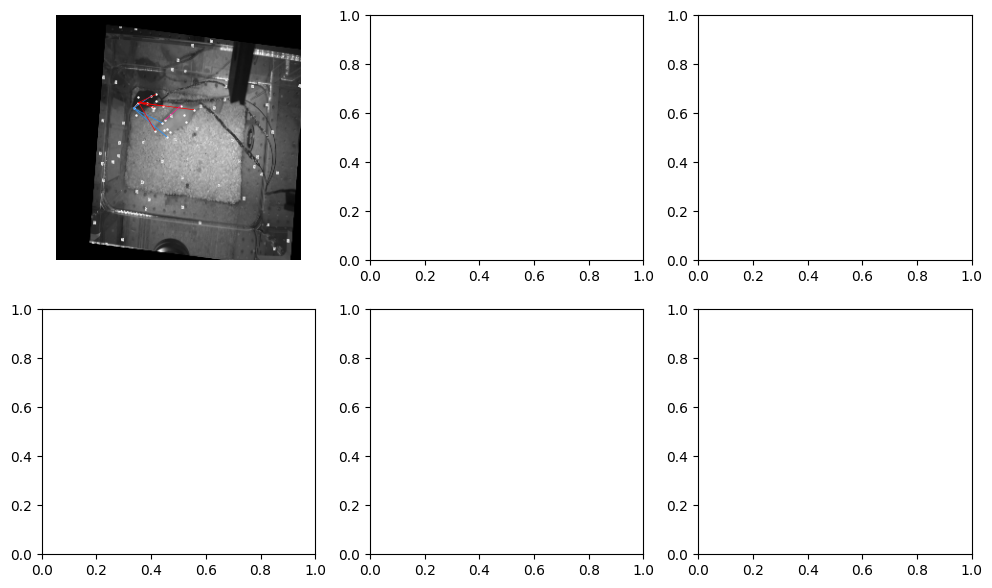

In [9]:
plot_camera_array(images_np, labels_np.reshape(dataset_object.num_views, -1))

In [10]:
np.nanmedian([2,3], axis=0)

np.float64(2.5)

In [11]:



import lightning.pytorch as pl
from lightning.pytorch import Trainer

# Add lightning-pose to path
sys.path.append('/teamspace/studios/this_studio/lightning-pose')

from lightning_pose.models.heatmap_tracker_multiview import HeatmapTrackerMultiviewTransformer
from lightning_pose.data.datasets import MultiviewHeatmapDataset
from lightning_pose.data.datamodules import BaseDataModule
from lightning_pose.data.datatypes import MultiviewHeatmapLabeledBatchDict
from lightning_pose.utils.predictions import load_model_from_checkpoint

# Assuming you have access to get_imgaug_transform from your library
from lightning_pose.utils.scripts import get_imgaug_transform 




Using device: cuda
Loaded augmentation transform: Sequential(name=UnnamedSequential, random_order=False, children=[Sometimes(p=AutoPrefetcher(nb_prefetch=10000, samples=None (dtype None), index=0, last_rng_idx=None, other_param=Binomial(Deterministic(float 0.40000000))), name=UnnamedSometimes, then_list=Sequential(name=UnnamedSometimes-then, random_order=False, children=[Affine(name=UnnamedAffine, parameters=[Deterministic(float 1.00000000), (Deterministic(int 0), None, 'px'), AutoPrefetcher(nb_prefetch=10000, samples=None (dtype None), index=0, last_rng_idx=None, other_param=Uniform(Deterministic(int -25), Deterministic(int 25))), Deterministic(float 0.00000000), Deterministic(int 1), Deterministic(int 0), Deterministic(constant), auto, False], deterministic=False)], deterministic=False), else_list=None, deterministic=False), Sometimes(p=AutoPrefetcher(nb_prefetch=10000, samples=None (dtype None), index=0, last_rng_idx=None, other_param=Binomial(Deterministic(float 0.50000000))), name

IndexError: index 27 is out of bounds for axis 0 with size 22

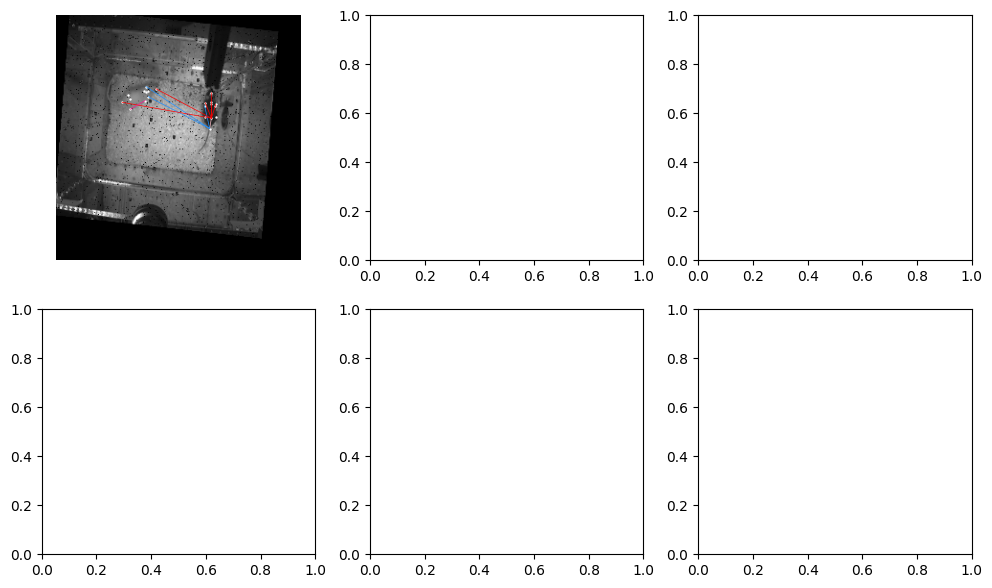

In [12]:

# --- Setup (Same as yours) ---
config_path = f"/teamspace/studios/this_studio/lp3d-analysis/configs/config_{dataset_name}.yaml"
cfg = OmegaConf.load(config_path)
cfg = DictConfig(cfg)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- FIX 1: Use the framework's augmentation getter ---
# This function reads 'imgaug: dlc' and 'imagug_3d: True' from your config
# and creates the correct 3D-aware augmentation pipeline object.
imgaug_transform = get_imgaug_transform(cfg)
print(f"Loaded augmentation transform: {imgaug_transform}")

# --- Dataset Setup (Mostly fine, but using the new transform) ---
# The MultiviewHeatmapDataset will use the camera_params_path and the 
# 3D-aware transform to apply the augmentations inside __getitem__.
dataset = MultiviewHeatmapDataset(
    root_directory=cfg.data.data_dir,
    csv_paths=cfg.data.csv_file,
    view_names=cfg.data.view_names,
    image_resize_height=cfg.data.image_resize_dims.height,
    image_resize_width=cfg.data.image_resize_dims.width,
    downsample_factor=cfg.data.downsample_factor,
    camera_params_path=cfg.data.camera_params_file,
    imgaug_transform=imgaug_transform,  # Pass the 3D-aware transform
    resize=False,  # Still False
)

# --- Datamodule Setup (Same as yours) ---
datamodule = BaseDataModule(
    dataset=dataset,
    train_batch_size=8,  # Use training batch size from config or larger
    val_batch_size=16,
    test_batch_size=1,
    train_probability=cfg.training.train_prob,
    val_probability=cfg.training.val_prob,
    test_probability=1.0 - cfg.training.train_prob - cfg.training.val_prob,
    num_workers=cfg.training.num_workers,
)

# Setup datamodule with stage argument
datamodule.setup(stage="fit")

# --- Pull and Visualize a Batch ---

# Get the training dataloader
train_loader = datamodule.train_dataloader()

# Get the first augmented batch
print("Pulling one batch from the training dataloader...")
batch = next(iter(train_loader))

# --- Extract and Prepare Data for Visualization ---
# batch['images'] shape is (Batch_Size, Num_Views, Color_Channels, Height, Width)
# batch['keypoints'] shape is (Batch_Size, Num_Views, Num_Keypoints, 2)
images_batch = batch['images'].cpu().numpy()
keypoints_batch = batch['keypoints'].cpu().numpy() 


# Select the first sample in the batch (index 0)
images_plot = images_batch[0, :, 0, :, :] # Select first batch item, all views, first channel
# Keypoints need to be flattened for the plot_camera_array function: (V, K*2)
keypoints_plot = keypoints_batch[0].reshape(images_plot.shape[0], -1) 

print(f"Visualizing batch of size {images_batch.shape[0]}.")
print(f"Images shape: {images_plot.shape}")
print(f"Keypoints shape: {keypoints_plot.shape}")

# Use your existing function to plot the augmented frames and keypoints
# This visualization will show the result of the 3D-aware rotation 
# applied to the keypoints and re-projected onto the image.
plot_camera_array(images_plot, keypoints_plot)
# plt.savefig("augmented_batch_visualization.png")
plt.show()

# You can also look at the target heatmaps if you wish
# heatmaps_batch = batch['heatmaps'].cpu().numpy()
# print(f"Heatmaps shape: {heatmaps_batch.shape}")

Pulling the first batch to skip it...
Pulling the second batch...
Visualizing the first sample of the second batch (Batch size: 8).


IndexError: index 27 is out of bounds for axis 0 with size 22

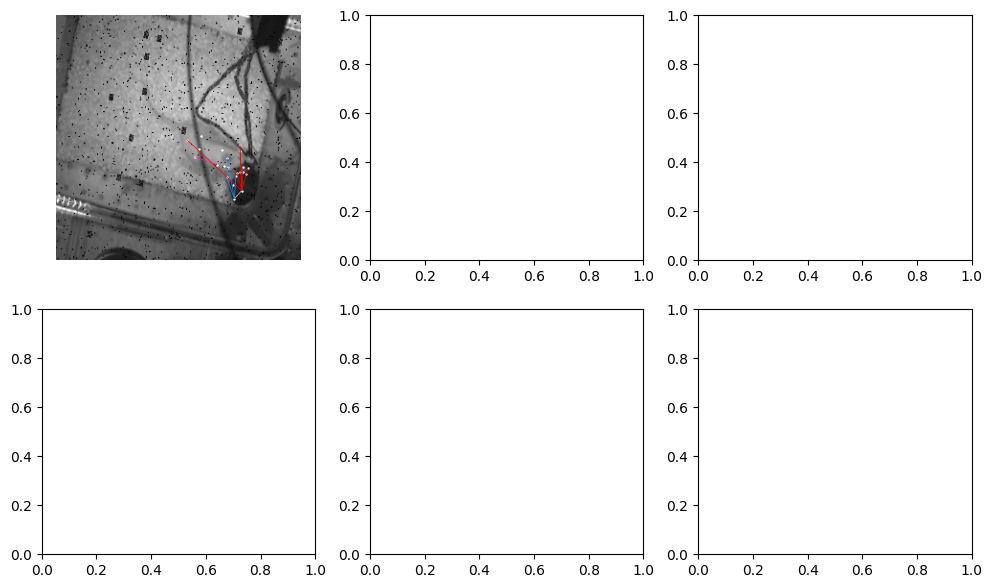

In [13]:
# --- Pull and Visualize the Second Batch ---

# 1. Get the training dataloader
train_loader = datamodule.train_dataloader()

# 2. Get the iterator from the dataloader
train_iterator = iter(train_loader)

print("Pulling the first batch to skip it...")
# 3. Pull the first batch (this advances the iterator)
_ = next(train_iterator) 

print("Pulling the second batch...")
# 4. Pull the second batch
batch_two = next(train_iterator)

# --- Extract and Prepare Data for Visualization ---
# Now use 'batch_two' for all subsequent operations

images_batch = batch_two['images'].cpu().numpy()
keypoints_batch = batch_two['keypoints'].cpu().numpy() 

# Select the first sample in the second batch (index 0)
images_plot = images_batch[0, :, 0, :, :] 
# Keypoints need to be flattened for the plot_camera_array function: (V, K*2)
keypoints_plot = keypoints_batch[0].reshape(images_plot.shape[0], -1) 

print(f"Visualizing the first sample of the second batch (Batch size: {images_batch.shape[0]}).")

# Use your existing function to plot the augmented frames and keypoints
plot_camera_array(images_plot, keypoints_plot)

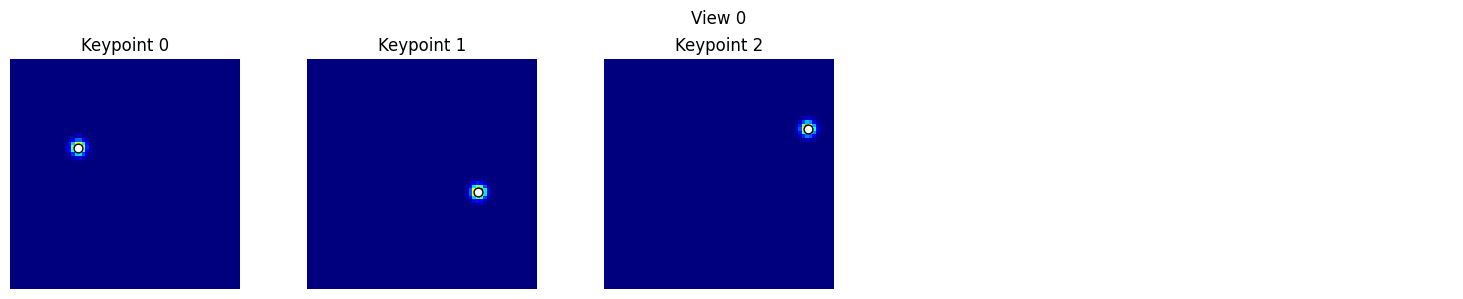

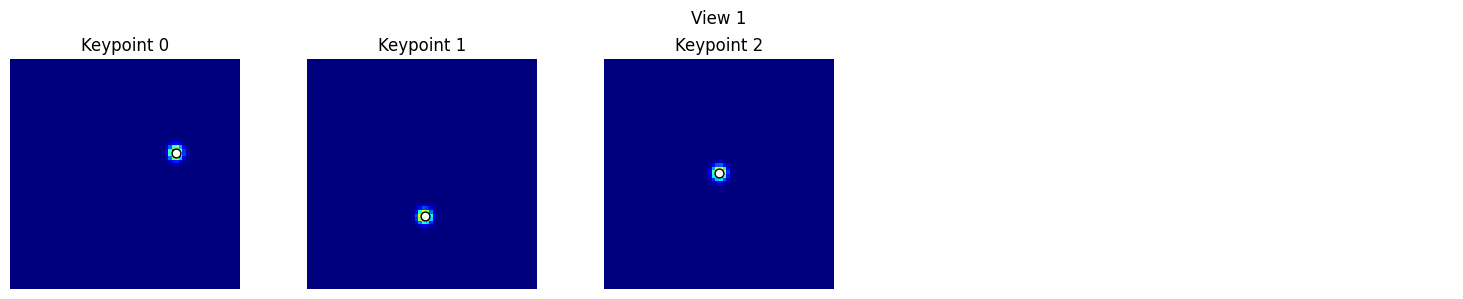

In [12]:
hh, hw = example_dict['heatmaps'].shape[-2:]
hmaps = example_dict['heatmaps'].reshape(dataset_object.num_views, -1, hh, hw).cpu().numpy()
labels = labels_np.reshape(dataset_object.num_views, -1, 2)
visualize_heatmaps(hmaps, labels, num_cols=5)

In [13]:

cfg_filepath = f'/teamspace/studios/this_studio/lp3d-analysis/configs/config_{dataset_name}.yaml'
cfg = OmegaConf.load(cfg_filepath)

# Get the data directory and CSV file paths
data_dir = Path(cfg.data.data_dir)
csv_paths = cfg.data.csv_file
view_names = list(cfg.data.view_names)
n_cams = len(view_names)

# Create output directory
output_dir = Path(f'/teamspace/studios/this_studio/ZZ_clean_images/{dataset_name}')
output_dir.mkdir(exist_ok=True)

# Load the first CSV to get image paths
first_csv_path = data_dir / csv_paths[0]
first_csv = pd.read_csv(first_csv_path)
image_paths = first_csv.iloc[:, 0].tolist()

# Process first 10 images
for idx in range(min(10, len(image_paths))):
    print(f"Processing frame {idx}")
    
    # Load images from all camera views
    images = []
    original_sizes = []
    
    for cam_idx, view_name in enumerate(view_names):
        # Get the corresponding CSV for this view
        csv_path = data_dir / csv_paths[cam_idx]
        df = pd.read_csv(csv_path)
        
        # Get the image path for this frame and view
        image_path = df.iloc[idx, 0]
        
        # Make sure the image path is absolute
        if not Path(image_path).is_absolute():
            image_path = data_dir / image_path
        
        # Load the raw image in original size
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        
        if image is not None:
            images.append(image)
            original_sizes.append(image.shape)  # Store original dimensions
            print(f"  {view_name}: {image.shape}")
        else:
            print(f"  Could not load image: {image_path}")
            # Create a black image as placeholder
            images.append(np.zeros((100, 100), dtype=np.uint8))
            original_sizes.append((100, 100))
    
    # Create combined image (2 rows, 3 columns for 6 cameras)
    rows, cols = 2, 3
    fig, axes = plt.subplots(rows, cols, figsize=(15, 10))  # Larger figure to accommodate original sizes
    axes = axes.flatten()
    
    # Plot each camera view in original size
    for i, (image, view_name) in enumerate(zip(images, view_names)):
        axes[i].imshow(image, cmap='gray')
        axes[i].axis('off')
        
        # Add camera name in top-left corner
        axes[i].text(
            10, 10, view_name,
            color='white', fontsize=12, weight='bold',
            ha='left', va='top',
            bbox=dict(facecolor='black', alpha=0.8)
        )
    
    # Hide unused subplots if any
    for i in range(n_cams, len(axes)):
        axes[i].axis('off')
    
    # Remove whitespace
    fig.subplots_adjust(left=0, right=1, top=0.98, bottom=0, wspace=0, hspace=0)
    plt.tight_layout()
    
    # Save the combined image
    output_path = output_dir / f'frame_{idx:03d}_all_views_original_size.pdf'
    plt.savefig(output_path, dpi=150, bbox_inches='tight', pad_inches=0)
    plt.close()  # Close the figure to free memory
    
    print(f"  Saved combined view: {output_path}")

print(f"Combined images saved to: {output_dir}")

Processing frame 0
  Could not load image: /teamspace/studios/data/ibl-mouse/bodyparts
  Could not load image: /teamspace/studios/data/ibl-mouse/bodyparts


[ WARN:0@14.379] global loadsave.cpp:275 findDecoder imread_('/teamspace/studios/data/ibl-mouse/bodyparts'): can't open/read file: check file path/integrity
[ WARN:0@14.475] global loadsave.cpp:275 findDecoder imread_('/teamspace/studios/data/ibl-mouse/bodyparts'): can't open/read file: check file path/integrity


  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_000_all_views_original_size.pdf
Processing frame 1
  Could not load image: /teamspace/studios/data/ibl-mouse/coords
  Could not load image: /teamspace/studios/data/ibl-mouse/coords


[ WARN:0@14.801] global loadsave.cpp:275 findDecoder imread_('/teamspace/studios/data/ibl-mouse/coords'): can't open/read file: check file path/integrity
[ WARN:0@14.875] global loadsave.cpp:275 findDecoder imread_('/teamspace/studios/data/ibl-mouse/coords'): can't open/read file: check file path/integrity


  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_001_all_views_original_size.pdf
Processing frame 2
  rightCamera: (256, 320)
  leftCamera: (256, 320)
  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_002_all_views_original_size.pdf
Processing frame 3
  rightCamera: (256, 320)
  leftCamera: (256, 320)
  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_003_all_views_original_size.pdf
Processing frame 4
  rightCamera: (256, 320)
  leftCamera: (256, 320)
  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_004_all_views_original_size.pdf
Processing frame 5
  rightCamera: (256, 320)
  leftCamera: (256, 320)
  Saved combined view: /teamspace/studios/this_studio/ZZ_clean_images/ibl-mouse/frame_005_all_views_original_size.pdf
Processing frame 6
  rightCamera: (256, 320)
  leftCamera: (256, 320)
  Saved combined view: /teamspace/studios/this_studio/ZZ_cle

In [14]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from omegaconf import OmegaConf, DictConfig
from lightning_pose.utils.scripts import get_imgaug_transform
from lightning_pose.data.datasets import MultiviewHeatmapDataset
from lightning_pose.data.datamodules import BaseDataModule
from lp3d_analysis.dataset_info import dataset_info

In [15]:
def plot_camera_array(frames, label_arrays, cam_names, skeleton, skeleton_colors=None, 
                      title=None, save_path=None):
    """Plot multi-view camera images with keypoints overlaid."""
    s = 0.5
    linewidth = 0.5
    txt_offset = 10
    height = 7
    n_views = len(frames)
    
    # Determine grid layout
    if n_views == 6:
        rows, cols = 2, 3
    elif n_views == 2:
        rows, cols = 1, 2
    elif n_views == 4:
        rows, cols = 2, 2
    else:
        rows = int(np.ceil(np.sqrt(n_views)))
        cols = int(np.ceil(n_views / rows))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, height))
    if n_views == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    # Loop through cameras
    for i, (frame, label_array) in enumerate(zip(frames, label_arrays)):
        # Extract x, y coordinates (alternating columns)
        x_coords = label_array[0::2]
        y_coords = label_array[1::2]

        # Plot the image
        axes[i].imshow(frame, cmap='gray')
        axes[i].axis('off')

        # Plot keypoints
        color = 'w' if skeleton_colors else 'r'
        axes[i].scatter(x_coords, y_coords, color=color, s=s)

        # Plot skeleton
        for l, limb in enumerate(skeleton):
            color = skeleton_colors[l] if skeleton_colors else 'r'
            axes[i].plot(x_coords[limb], y_coords[limb], color, linewidth=linewidth)

        # Add camera name
        axes[i].text(
            txt_offset, txt_offset, cam_names[i],
            color='white', fontsize=12, weight='bold',
            ha='left', va='top',
            bbox=dict(facecolor='black', alpha=0.8)
        )
    
    # Hide unused subplots
    for i in range(n_views, len(axes)):
        axes[i].axis('off')

    # Remove whitespace
    fig.subplots_adjust(left=0, right=1, top=0.95, bottom=0, wspace=0, hspace=0)
    
    if title:
        fig.suptitle(title, fontsize=14, y=0.98)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved figure to: {save_path}")
    
    plt.show()

In [16]:

# Load config
cfg_filepath = f'/teamspace/studios/this_studio/lp3d-analysis/configs/config_{dataset_name}.yaml'
cfg = OmegaConf.load(cfg_filepath)
cfg = DictConfig(cfg)

# Get dataset metadata
data_info = dataset_info[dataset_name.replace('-crop', '')]
cam_names = data_info['cam_names']
skeleton = data_info['skeleton']
skeleton_colors = data_info['skeleton_colors']

print(f"Dataset: {dataset_name}")
print(f"Number of cameras: {len(cam_names)}")
print(f"Camera names: {cam_names}")

Dataset: ibl-mouse
Number of cameras: 2
Camera names: ['rightCamera', 'leftCamera']


In [17]:
# Get 3D-aware augmentation transform
imgaug_transform = get_imgaug_transform(cfg)
print(f"Augmentation enabled: {cfg.training.imgaug}")
print(f"3D augmentation enabled: {cfg.training.get('imgaug_3d', False)}")

# Create dataset with augmentations
dataset_aug = MultiviewHeatmapDataset(
    root_directory=cfg.data.data_dir,
    csv_paths=cfg.data.csv_file,
    view_names=cfg.data.view_names,
    image_resize_height=cfg.data.image_resize_dims.height,
    image_resize_width=cfg.data.image_resize_dims.width,
    downsample_factor=cfg.data.downsample_factor,
    camera_params_path=cfg.data.camera_params_file,
    imgaug_transform=imgaug_transform,
    resize=False,
)

# Create datamodule
datamodule = BaseDataModule(
    dataset=dataset_aug,
    train_batch_size=8,
    val_batch_size=16,
    test_batch_size=1,
    train_probability=cfg.training.train_prob,
    val_probability=cfg.training.val_prob,
    test_probability=1.0 - cfg.training.train_prob - cfg.training.val_prob,
    num_workers=cfg.training.num_workers,
)

datamodule.setup(stage="fit")
print("Dataset and datamodule ready!")

Augmentation enabled: dlc
3D augmentation enabled: True
Using MultiviewHeatmapDataset
Number of labeled images in the full dataset (train+val+test): 640
val: updating children datasets with resize imgaug pipeline
test: updating children datasets with resize imgaug pipeline
Dataset splits -- train: 608, val: 32, test: 0
Dataset and datamodule ready!


/teamspace/studios/this_studio/lightning-pose/lightning_pose/data/cameras.py:209: All-NaN slice encountered
/teamspace/studios/this_studio/lightning-pose/lightning_pose/data/cameras.py:209: All-NaN slice encountered
/teamspace/studios/this_studio/lightning-pose/lightning_pose/data/cameras.py:209: All-NaN slice encountered


Batch shape: (8, 2, 3, 256, 256)
Keypoints shape: (8, 12)

--- Sample 1 ---


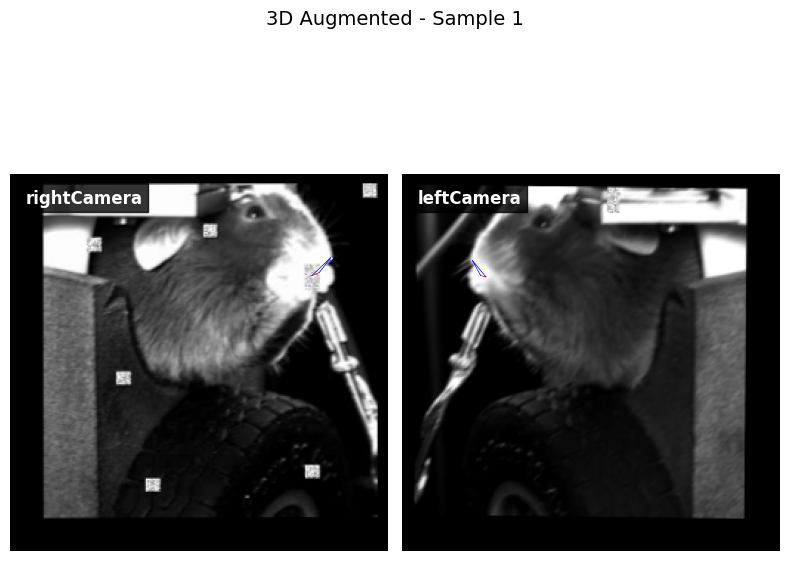


--- Sample 2 ---


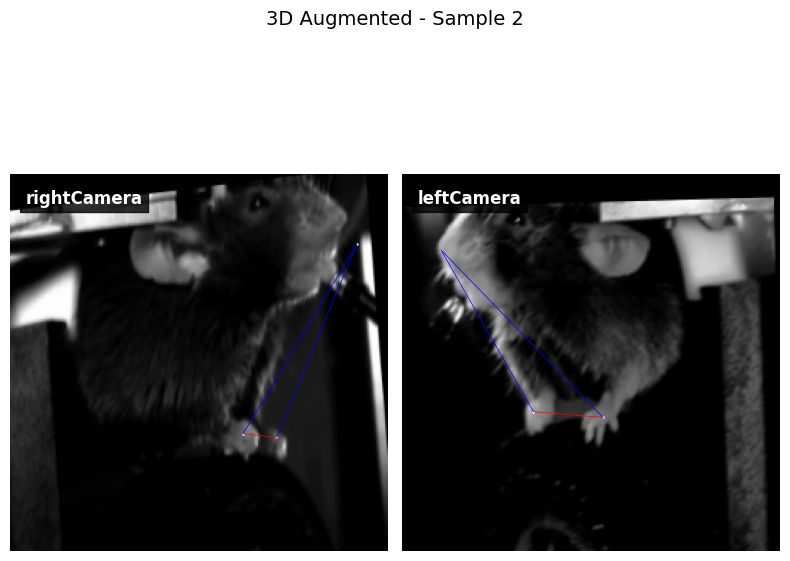


--- Sample 3 ---


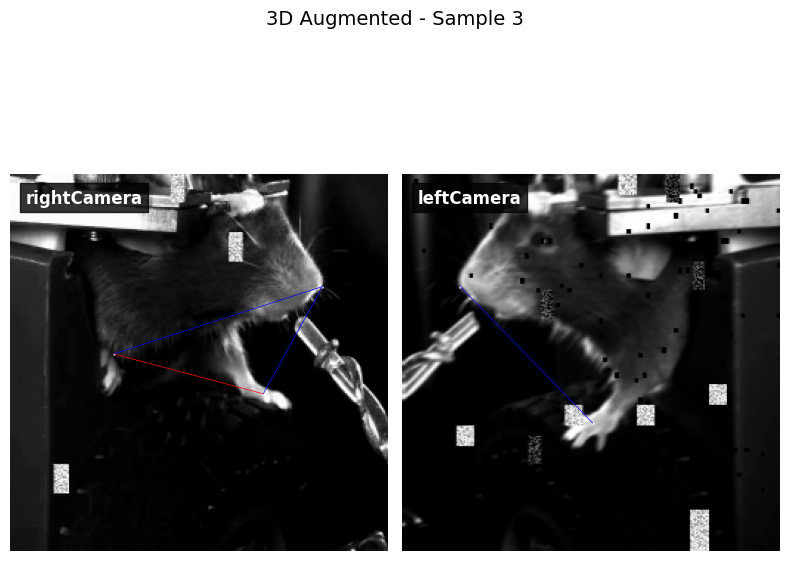

In [18]:
# Get training dataloader
train_loader = datamodule.train_dataloader()

# Pull a random batch
batch = next(iter(train_loader))

# Extract data
images_batch = batch['images'].cpu().numpy()  # (B, V, C, H, W)
keypoints_batch = batch['keypoints'].cpu().numpy()  # (B, V, K, 2)

print(f"Batch shape: {images_batch.shape}")
print(f"Keypoints shape: {keypoints_batch.shape}")

# Visualize first 3 samples from the batch
num_samples_to_show = min(3, images_batch.shape[0])

for sample_idx in range(num_samples_to_show):
    print(f"\n--- Sample {sample_idx + 1} ---")
    
    # Extract images and keypoints for this sample
    images_plot = images_batch[sample_idx, :, 0, :, :]  # (V, H, W)
    keypoints_plot = keypoints_batch[sample_idx].reshape(len(cam_names), -1)  # (V, K*2)
    
    # Plot with 3D augmentations applied
    plot_camera_array(
        images_plot, 
        keypoints_plot,
        cam_names,
        skeleton,
        skeleton_colors,
        title=f"3D Augmented - Sample {sample_idx + 1}"
    )

In [19]:
# Modified Cell to show what augmentation is ACTUALLY being applied
print(f"Config says (raw value): {cfg.training.imgaug}")
print(f"3D aug flag: {cfg.training.get('imgaug_3d', False)}")

# Manually replicate the logic from get_imgaug_transform
params = cfg.training.get("imgaug", "default")
imgaug_3d = cfg.training.get("imgaug_3d", None)

if (
    params not in ["default", "none"]
    and cfg.model.model_type.find("multiview") > -1
    and cfg.data.get("camera_params_file")
    and (imgaug_3d is True or imgaug_3d is None)
):
    params_actual = "dlc-mv"
else:
    params_actual = params

print(f"\nActual augmentation pipeline selected: {params_actual}")
print(f"\nModel type: {cfg.model.model_type}")
print(f"Has 'multiview' in model_type: {'multiview' in cfg.model.model_type}")
print(f"Camera params file exists: {cfg.data.get('camera_params_file') is not None}")

# Check what the actual transform looks like
print(f"\nActual augmentation pipeline type: {type(imgaug_transform)}")

# Check if rotation/elastic transforms are present (they shouldn't be for dlc-mv)
aug_str = str(imgaug_transform)
has_rotation = "Affine" in aug_str or "Rotate" in aug_str
has_elastic = "ElasticTransformation" in aug_str
has_crop = "Crop" in aug_str

print(f"\nPipeline analysis:")
print(f"  Has Rotation/Affine: {has_rotation}")
print(f"  Has Elastic Transform: {has_elastic}")
print(f"  Has Crop: {has_crop}")

if not has_rotation and not has_elastic and not has_crop:
    print("\n✅ SUCCESS! This is a 3D-compatible augmentation pipeline (dlc-mv)")
    print("   (No geometric transforms that would break 3D consistency)")
else:
    print("\n⚠️ WARNING! This pipeline has geometric transforms that break 3D consistency")

Config says (raw value): dlc
3D aug flag: True

Actual augmentation pipeline selected: dlc-mv

Model type: heatmap_multiview_transformer
Has 'multiview' in model_type: True
Camera params file exists: True

Actual augmentation pipeline type: <class 'imgaug.augmenters.meta.Sequential'>

Pipeline analysis:
  Has Rotation/Affine: False
  Has Elastic Transform: False
  Has Crop: False

✅ SUCCESS! This is a 3D-compatible augmentation pipeline (dlc-mv)
   (No geometric transforms that would break 3D consistency)


Showing 6 different augmentations of sample 20

Augmentation 1/6


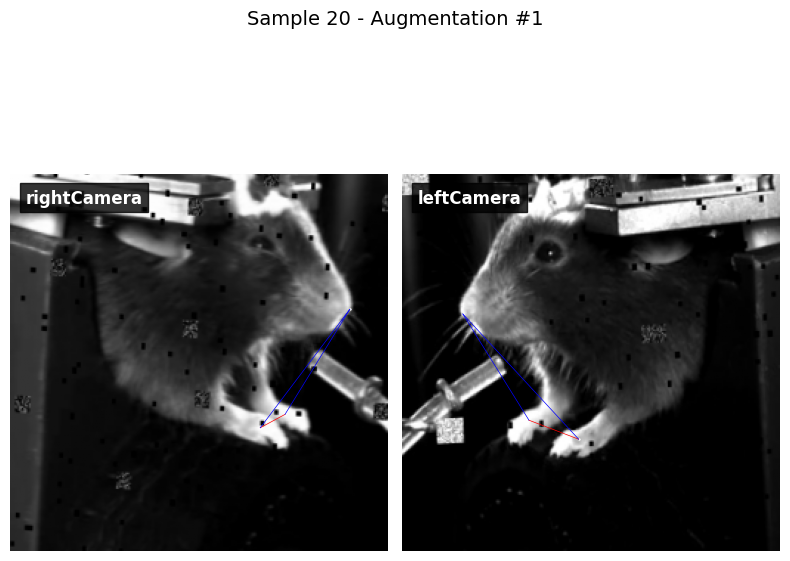


Augmentation 2/6


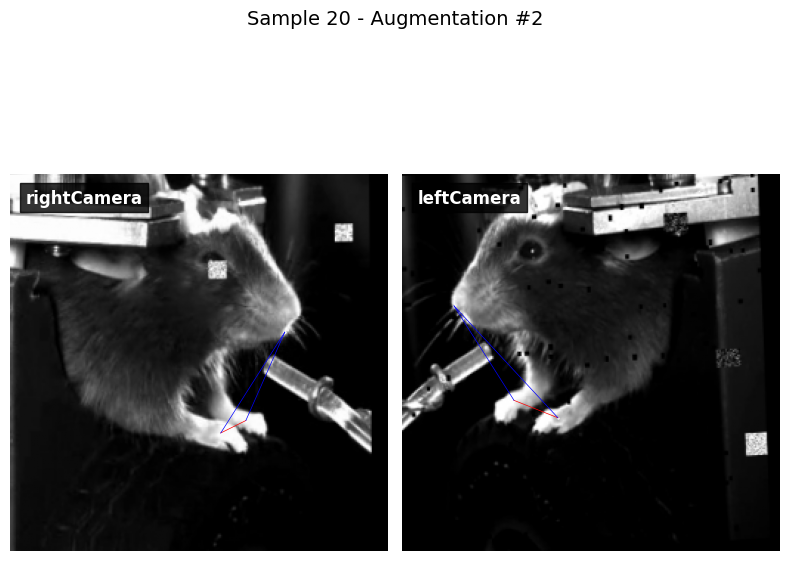


Augmentation 3/6


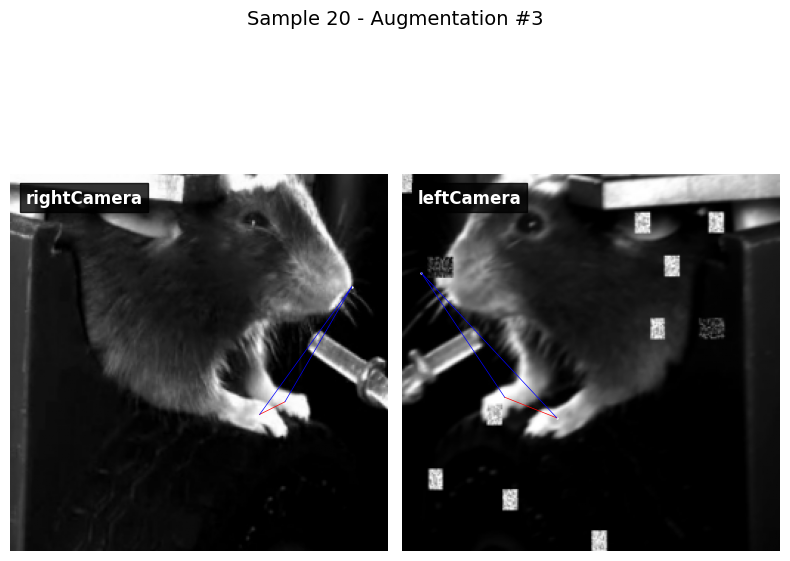


Augmentation 4/6


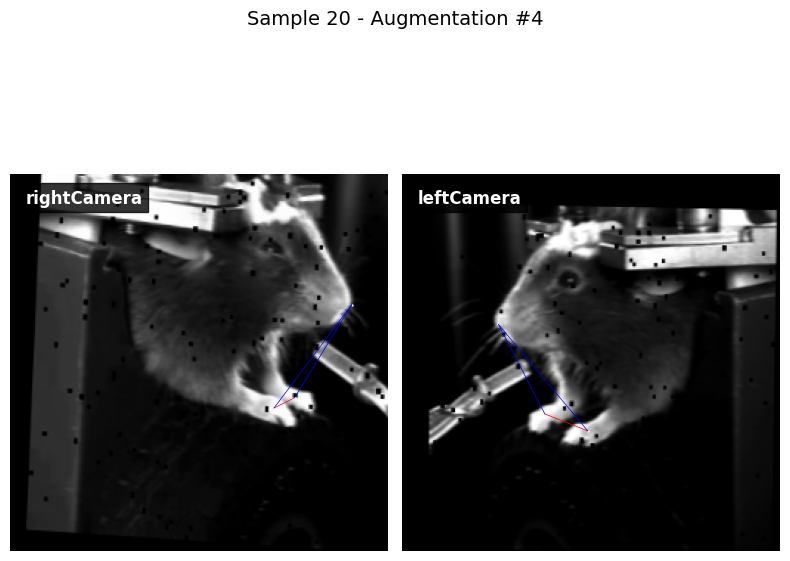


Augmentation 5/6


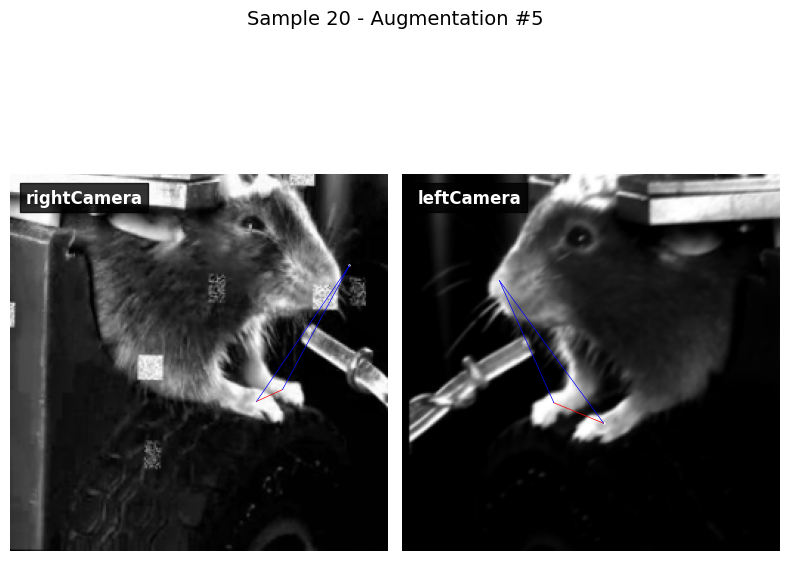


Augmentation 6/6


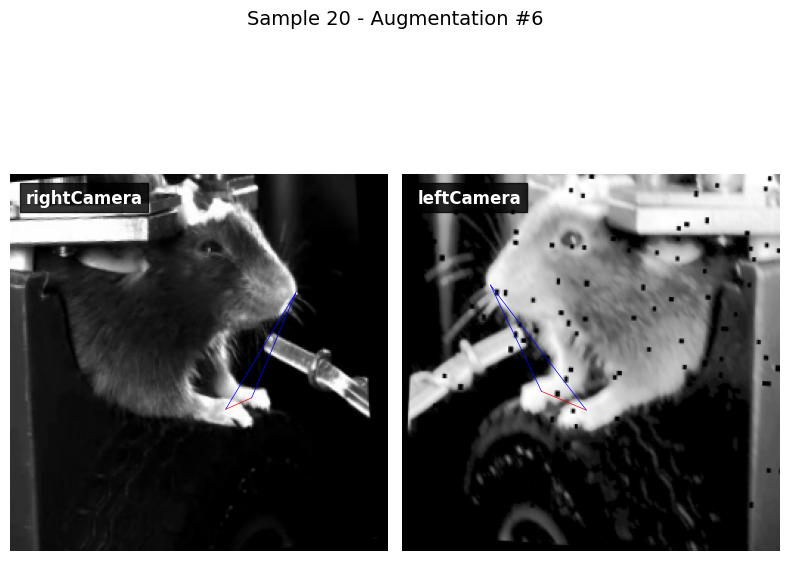

In [20]:
# Choose a sample index to augment multiple times
sample_idx = 20  # Change this to any sample you want

# Number of different augmentations to show
num_augmentations = 6

print(f"Showing {num_augmentations} different augmentations of sample {sample_idx}")
print("="*80)

# Pull the same sample multiple times (each pull applies random augmentation)
for aug_num in range(num_augmentations):
    print(f"\nAugmentation {aug_num + 1}/{num_augmentations}")
    
    # Each time we access the dataset, augmentation is applied randomly
    sample_aug = dataset_aug[sample_idx]
    images_aug = sample_aug['images'].cpu().numpy()[:, 0, :, :]
    keypoints_aug = sample_aug['keypoints'].reshape(len(cam_names), -1).cpu().numpy()
    
    # Plot this augmented version
    plot_camera_array(
        images_aug, 
        keypoints_aug,
        cam_names,
        skeleton,
        skeleton_colors,
        title=f"Sample {sample_idx} - Augmentation #{aug_num + 1}"
    )

# Reprojecting Data visualization to udnerstand the performance of each session 

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from aniposelib.cameras import CameraGroup
from omegaconf import OmegaConf
import cv2
from collections import defaultdict

In [ ]:
dataset_name = 'ibl-mouse'

# Load config
cfg_filepath = f'/teamspace/studios/this_studio/lp3d-analysis/configs/config_{dataset_name}.yaml'
cfg = OmegaConf.load(cfg_filepath)

# Get dataset info
from lp3d_analysis.dataset_info import dataset_info
data_info = dataset_info[dataset_name.replace('-crop', '')]
cam_names = data_info['cam_names']
skeleton = data_info['skeleton']
skeleton_colors = data_info['skeleton_colors']

# # Load camera parameters mapping CSV
# data_dir = Path(cfg.data.data_dir)
# camera_params_csv = Path(cfg.data.camera_params_file)

# print(f"Loading camera parameters mapping from: {camera_params_csv}")

# # Load the CSV that maps images to calibration files
# calib_df = pd.read_csv(camera_params_csv, index_col=0)
# print(f"Found {len(calib_df)} image-to-calibration mappings")


# Load camera parameters mapping CSV
data_dir = "/teamspace/studios/data/ibl-mouse"
camera_params_csv = "/teamspace/studios/data/ibl-mouse/calibrations.csv"

print(f"Loading camera parameters mapping from: {camera_params_csv}")

# Load the CSV that maps images to calibration files
calib_df = pd.read_csv(camera_params_csv, index_col=0)
print(f"Found {len(calib_df)} image-to-calibration mappings")


# Group images by their calibration file
sessions = defaultdict(list)
for img_path, calib_file in calib_df.iterrows():
    sessions[calib_file['file']].append(img_path)

print(f"\nFound {len(sessions)} unique calibration sessions:")
for calib_file, images in sessions.items():
    print(f"  {Path(calib_file).name}: {len(images)} images")

Loading camera parameters mapping from: /teamspace/studios/data/ibl-mouse/calibrations.csv
Found 640 image-to-calibration mappings

Found 16 unique calibration sessions:
  _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c.toml: 40 images
  _iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd.toml: 40 images
  _iblrig.downsampled.a7763417-e0d6-4f2a-aa55-e382fd9b5fb8.toml: 40 images
  _iblrig.downsampled.72cb5550-43b4-4ef0-add5-e4adfdfb5e02.toml: 40 images
  _iblrig.downsampled.781b35fd-e1f0-4d14-b2bb-95b7263082bb.toml: 40 images
  _iblrig.downsampled.d2832a38-27f6-452d-91d6-af72d794136c.toml: 40 images
  _iblrig.downsampled.dac3a4c1-b666-4de0-87e8-8c514483cacf.toml: 40 images
  _iblrig.downsampled.dda5fc59-f09a-4256-9fb5-66c67667a466.toml: 40 images
  _iblrig.downsampled.e2b845a1-e313-4a08-bc61-a5f662ed295e.toml: 40 images
  _iblrig.downsampled.e45481fa-be22-4365-972c-e7404ed8ab5a.toml: 40 images
  _iblrig.downsampled.ecb5520d-1358-434c-95ec-93687ecd1396.toml: 40 images
  _ib

In [23]:
# Cell: Load ALL Images from Calibration CSV (Including Unlabeled)
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
import re

print(f"Loading camera parameters mapping from: {camera_params_csv}")
calib_df = pd.read_csv(camera_params_csv, index_col=0)
print(f"Found {len(calib_df)} image-to-calibration mappings in total")

# Load keypoint CSV files (these contain only LABELED frames)
# csv_paths = cfg.data.csv_file # this is for InD data 

# this is for OOD data 
csv_paths = []
for view in cfg.data.view_names:
    csv_paths.append(f"/teamspace/studios/data/ibl-mouse/CollectedData_{view}.csv")
    
print(f"\nLoading keypoint data from {len(csv_paths)} views...")

keypoints_by_view = []
image_paths_by_view = []

for view_idx, csv_file in enumerate(csv_paths):
    csv_path = os.path.join(data_dir, csv_file)
    print(f"csv_path: {csv_path}")
    df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    
    from lightning_pose.utils.io import fix_empty_first_row
    df = fix_empty_first_row(df)
    
    keypoints_2d = df.to_numpy().reshape(df.shape[0], -1, 2)
    keypoints_by_view.append(keypoints_2d)
    image_paths_by_view.append(df.index.tolist())
    
    print(f"  View {view_idx} ({cam_names[view_idx]}): {keypoints_2d.shape[0]} labeled frames")

n_views = len(keypoints_by_view)
n_keypoints = keypoints_by_view[0].shape[1]

def extract_session_and_filename(path):
    """Extract filename for matching."""
    p = Path(path)
    filename = p.name
    
    uuid_pattern = r'([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})'
    match = re.search(uuid_pattern, str(p.parent))
    
    if match:
        return (match.group(1), filename)
    else:
        return ('', filename)

# Create mappings for LABELED frames only
labeled_maps = []
for view_idx in range(n_views):
    view_map = {}
    for i, img_path in enumerate(image_paths_by_view[view_idx]):
        key = extract_session_and_filename(img_path)
        if key:
            view_map[key] = i
    labeled_maps.append(view_map)
    print(f"View {view_idx} labeled frames: {len(view_map)}")

# Group ALL images by calibration session (from calib_df)
sessions = defaultdict(list)
for img_path, row in calib_df.iterrows():
    sessions[row['file']].append(img_path)

print(f"\nFound {len(sessions)} unique calibration sessions:")
for calib_file, images in sessions.items():
    print(f"  {Path(calib_file).name}: {len(images)} images (labeled + unlabeled)")

# Create session data INCLUDING ALL IMAGES (labeled or not)
session_data = {}

for calib_file, all_session_images in sessions.items():
    session_name = Path(calib_file).stem
    
    # Get keys for ALL images in this session
    all_keys = []
    for img_path in all_session_images:
        key = extract_session_and_filename(img_path)
        if key:
            all_keys.append((key, img_path))
    
    if len(all_keys) == 0:
        continue
    
    n_frames = len(all_keys)
    
    # Initialize arrays with NaN (for all frames, all views, all keypoints)
    session_keypoints = np.full((n_frames, n_views, n_keypoints, 2), np.nan)
    session_image_paths = [[] for _ in range(n_views)]
    
    labeled_count = 0
    unlabeled_count = 0
    
    for frame_idx, (key, original_img_path) in enumerate(all_keys):
        has_any_labels = False
        
        for view_idx in range(n_views):
            # Check if this frame has labels in this view
            if key in labeled_maps[view_idx]:
                # Frame is labeled in this view
                label_idx = labeled_maps[view_idx][key]
                session_keypoints[frame_idx, view_idx] = keypoints_by_view[view_idx][label_idx]
                session_image_paths[view_idx].append(image_paths_by_view[view_idx][label_idx])
                has_any_labels = True
            else:
                # Frame is NOT labeled in this view - use original path, keep NaN keypoints
                session_image_paths[view_idx].append(original_img_path)
        
        if has_any_labels:
            labeled_count += 1
        else:
            unlabeled_count += 1
    
    session_data[calib_file] = {
        'keypoints_2d': session_keypoints,
        'image_paths': session_image_paths,
        'keys': [k for k, _ in all_keys]
    }
    
    print(f"\nSession {session_name}:")
    print(f"  Total frames: {n_frames}")
    print(f"  Frames with labels: {labeled_count}")
    print(f"  Frames without labels: {unlabeled_count}")
    print(f"  Keypoints shape: {session_keypoints.shape}")

total_frames = sum(data['keypoints_2d'].shape[0] for data in session_data.values())
print(f"\n{'='*80}")
print(f"Total sessions: {len(session_data)}")
print(f"Total frames (labeled + unlabeled): {total_frames}")
print(f"{'='*80}")

Loading camera parameters mapping from: /teamspace/studios/data/ibl-mouse/calibrations.csv
Found 640 image-to-calibration mappings in total

Loading keypoint data from 2 views...
csv_path: /teamspace/studios/data/ibl-mouse/CollectedData_rightCamera.csv
  View 0 (rightCamera): 640 labeled frames
csv_path: /teamspace/studios/data/ibl-mouse/CollectedData_leftCamera.csv
  View 1 (leftCamera): 640 labeled frames
View 0 labeled frames: 640
View 1 labeled frames: 640

Found 16 unique calibration sessions:
  _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c.toml: 40 images (labeled + unlabeled)
  _iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd.toml: 40 images (labeled + unlabeled)
  _iblrig.downsampled.a7763417-e0d6-4f2a-aa55-e382fd9b5fb8.toml: 40 images (labeled + unlabeled)
  _iblrig.downsampled.72cb5550-43b4-4ef0-add5-e4adfdfb5e02.toml: 40 images (labeled + unlabeled)
  _iblrig.downsampled.781b35fd-e1f0-4d14-b2bb-95b7263082bb.toml: 40 images (labeled + unlabeled)
  _iblrig.d

In [24]:
# # Cell: Load and Match Data - INCLUDE ALL FRAMES (Updated)
# import pandas as pd
# import numpy as np
# from pathlib import Path
# from collections import defaultdict
# import re

# '''
# for inD data 
# '''
# csv_paths = cfg.data.csv_file
# print(f"Loading keypoint data from {len(csv_paths)} views...")

# # Load all keypoint data
# keypoints_by_view = []
# image_paths_by_view = []

# for view_idx, csv_file in enumerate(csv_paths):
#     csv_path = data_dir / csv_file
#     print(f"csv_path: {csv_path}")
#     df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    
#     # Fix empty first row if needed
#     from lightning_pose.utils.io import fix_empty_first_row
#     df = fix_empty_first_row(df)
    
#     # Extract x, y coordinates
#     keypoints_2d = df.to_numpy().reshape(df.shape[0], -1, 2)  # (n_frames, n_keypoints, 2)
#     keypoints_by_view.append(keypoints_2d)
#     image_paths_by_view.append(df.index.tolist())
    
#     print(f"  View {view_idx} ({cam_names[view_idx]}): {keypoints_2d.shape}")

# n_views = len(keypoints_by_view)
# n_keypoints = keypoints_by_view[0].shape[1]

# # Function to extract session and filename for matching
# def extract_session_and_filename(path):
#     """Extract filename for matching (ignores session for single-calibration datasets)."""
#     p = Path(path)
#     filename = p.name
    
#     # Check if it's IBL data with UUID
#     uuid_pattern = r'([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})'
#     match = re.search(uuid_pattern, str(p.parent))
    
#     if match:
#         # IBL format: return (uuid, filename)
#         return (match.group(1), filename)
#     else:
#         # Chickadee format: return (empty_session, filename) for matching by filename only
#         return ('', filename)

# # Create mapping for ALL views: (session_uuid, filename) -> index
# view_path_maps = []
# for view_idx in range(n_views):
#     view_map = {}
#     for i, img_path in enumerate(image_paths_by_view[view_idx]):
#         key = extract_session_and_filename(img_path)
#         if key:
#             view_map[key] = i
#     view_path_maps.append(view_map)
#     print(f"View {view_idx} mapping: {len(view_map)} entries")

# # Get ALL unique image keys across all views
# all_keys = set()
# for view_map in view_path_maps:
#     all_keys.update(view_map.keys())
# print(f"\nTotal unique images across all views: {len(all_keys)}")

# # Group by session (from calibration CSV)
# sessions = defaultdict(list)
# for img_path, calib_file in calib_df.iterrows():
#     sessions[calib_file['file']].append(img_path)

# print(f"\nFound {len(sessions)} unique calibration sessions:")
# for calib_file, images in sessions.items():
#     print(f"  {Path(calib_file).name}: {len(images)} images")

# # Now create session data INCLUDING ALL FRAMES
# session_data = {}

# for calib_file, session_images in sessions.items():
#     # Get all keys for this session
#     session_keys = []
#     for img in session_images:
#         key = extract_session_and_filename(img)
#         if key:
#             session_keys.append(key)
    
#     if len(session_keys) == 0:
#         continue
    
#     # For each key, get indices from each view (or None if not present)
#     session_frame_data = []
#     valid_keys = []
    
#     for key in session_keys:
#         # Check if this key exists in at least one view
#         exists_in_any_view = any(key in view_path_maps[v] for v in range(n_views))
        
#         if exists_in_any_view:
#             frame_indices = []
#             for view_idx in range(n_views):
#                 if key in view_path_maps[view_idx]:
#                     frame_indices.append(view_path_maps[view_idx][key])
#                 else:
#                     frame_indices.append(None)
            
#             session_frame_data.append(frame_indices)
#             valid_keys.append(key)
    
#     if len(valid_keys) > 0:
#         # Collect keypoints for this session from all views
#         # Handle missing frames by using NaN
#         n_frames = len(valid_keys)
#         session_keypoints = np.full((n_frames, n_views, n_keypoints, 2), np.nan)
#         session_image_paths = [[] for _ in range(n_views)]
        
#         for frame_idx, (key, indices) in enumerate(zip(valid_keys, session_frame_data)):
#             for view_idx in range(n_views):
#                 if indices[view_idx] is not None:
#                     # Frame exists in this view
#                     idx = indices[view_idx]
#                     session_keypoints[frame_idx, view_idx] = keypoints_by_view[view_idx][idx]
#                     session_image_paths[view_idx].append(image_paths_by_view[view_idx][idx])
#                 else:
#                     # Frame doesn't exist in this view - already filled with NaN
#                     # Use a placeholder path
#                     session_image_paths[view_idx].append(f"missing_frame_{key}")
        
#         session_data[calib_file] = {
#             'keypoints_2d': session_keypoints,
#             'image_paths': session_image_paths,
#             'keys': valid_keys,
#             'frame_indices': session_frame_data
#         }
        
#         session_name = Path(calib_file).stem
#         print(f"\nSession {session_name}:")
#         print(f"  Frames: {session_keypoints.shape[0]}")
#         print(f"  Keypoints shape: {session_keypoints.shape}")
        
#         # Count frames with missing views
#         missing_view_count = sum(1 for indices in session_frame_data if None in indices)
#         if missing_view_count > 0:
#             print(f"  Frames with missing views: {missing_view_count}")

# print(f"\n{'='*80}")
# print(f"Total sessions with data: {len(session_data)}")
# print(f"{'='*80}")

In [25]:
# Cell: Triangulate and Reproject - HANDLE ALL FRAMES (Updated)
from tqdm import tqdm
import os

def triangulate_and_reproject(keypoints_2d, cam_group):
    """
    Triangulate 2D to 3D and reproject back to 2D.
    Handles missing/unlabeled keypoints gracefully.
    
    Args:
        keypoints_2d: (n_frames, n_views, n_keypoints, 2)
        cam_group: CameraGroup
    
    Returns:
        keypoints_3d: (n_frames, n_keypoints, 3)
        keypoints_2d_reproj: (n_frames, n_views, n_keypoints, 2)
        errors: (n_frames, n_views, n_keypoints)
    """
    n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
    keypoints_3d = np.full((n_frames, n_keypoints, 3), np.nan)
    keypoints_2d_reproj = np.full((n_frames, n_views, n_keypoints, 2), np.nan)
    
    # Triangulate
    for frame_idx in range(n_frames):
        for kp_idx in range(n_keypoints):
            points_2d = keypoints_2d[frame_idx, :, kp_idx, :]
            valid_mask = ~np.isnan(points_2d).any(axis=1)
            
            # Only triangulate if we have at least 2 valid views
            if valid_mask.sum() >= 2:
                points_2d_valid = points_2d[valid_mask]
                try:
                    point_3d = cam_group.triangulate(points_2d_valid, progress=False)
                    keypoints_3d[frame_idx, kp_idx] = point_3d
                    
                    # Reproject to all views (even if they were missing in original)
                    for view_idx, camera in enumerate(cam_group.cameras):
                        point_2d = camera.project(point_3d)
                        keypoints_2d_reproj[frame_idx, view_idx, kp_idx] = point_2d
                except:
                    # If triangulation fails, leave as NaN
                    pass
            # If less than 2 views, leave as NaN (already initialized)
    
    # Compute errors (only where both original and reprojection exist)
    diff = keypoints_2d - keypoints_2d_reproj
    errors = np.sqrt(np.sum(diff**2, axis=-1))
    
    return keypoints_3d, keypoints_2d_reproj, errors


# Analyze each session - INCLUDE ALL FRAMES
session_results = {}

print("Processing sessions (including ALL frames)...")
for calib_file, data in session_data.items():
    session_name = Path(calib_file).stem
    print(f"\n{'='*80}")
    print(f"Processing: {session_name}")
    print(f"{'='*80}")
    print(f"calib_file: {calib_file}")
    
    # Load camera group for this session
    # calib_path = data_dir / calib_file # for InD data 
    calib_path = os.path.join(data_dir, calib_file) # for OOD data 
    cam_group = CameraGroup.load(str(calib_path))
    print(f"Loaded {len(cam_group.cameras)} cameras")
    
    # Triangulate and reproject (handles NaN gracefully)
    keypoints_3d, keypoints_2d_reproj, errors = triangulate_and_reproject(
        data['keypoints_2d'], 
        cam_group
    )
    
    # Store results
    session_results[session_name] = {
        'cam_group': cam_group,
        'keypoints_2d': data['keypoints_2d'],
        'keypoints_2d_reproj': keypoints_2d_reproj,
        'keypoints_3d': keypoints_3d,
        'errors': errors,
        'image_paths': data['image_paths'],
        'keys': data['keys']
    }
    
    # Print statistics (excluding NaN)
    print(f"\nReprojection Error Statistics:")
    valid_errors = errors[~np.isnan(errors)]
    if len(valid_errors) > 0:
        print(f"  Mean: {np.nanmean(valid_errors):.3f} pixels")
        print(f"  Median: {np.nanmedian(valid_errors):.3f} pixels")
        print(f"  Std: {np.nanstd(valid_errors):.3f} pixels")
        print(f"  Max: {np.nanmax(valid_errors):.3f} pixels")
        print(f"  Valid measurements: {len(valid_errors)}")
    else:
        print(f"  No valid reprojections")
    
    # Per-view stats
    print(f"\n  Per-view:")
    for view_idx, cam_name in enumerate(cam_names):
        view_err = errors[:, view_idx, :]
        valid_view_err = view_err[~np.isnan(view_err)]
        if len(valid_view_err) > 0:
            print(f"    {cam_name}: {np.nanmean(valid_view_err):.3f} ± {np.nanstd(valid_view_err):.3f} px ({len(valid_view_err)} valid)")
        else:
            print(f"    {cam_name}: No valid data")

print(f"\n{'='*80}")
print(f"✅ Completed analysis for {len(session_results)} sessions")
print(f"{'='*80}")

Processing sessions (including ALL frames)...

Processing: _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c
calib_file: calibrations/_iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c.toml


Loaded 2 cameras

Reprojection Error Statistics:
  Mean: 0.000 pixels
  Median: 0.000 pixels
  Std: 0.000 pixels
  Max: 0.000 pixels
  Valid measurements: 240

  Per-view:
    rightCamera: 0.000 ± 0.000 px (120 valid)
    leftCamera: 0.000 ± 0.000 px (120 valid)

Processing: _iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd
calib_file: calibrations/_iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd.toml
Loaded 2 cameras

Reprojection Error Statistics:
  Mean: 0.000 pixels
  Median: 0.000 pixels
  Std: 0.000 pixels
  Max: 0.000 pixels
  Valid measurements: 220

  Per-view:
    rightCamera: 0.000 ± 0.000 px (110 valid)
    leftCamera: 0.000 ± 0.000 px (110 valid)

Processing: _iblrig.downsampled.a7763417-e0d6-4f2a-aa55-e382fd9b5fb8
calib_file: calibrations/_iblrig.downsampled.a7763417-e0d6-4f2a-aa55-e382fd9b5fb8.toml
Loaded 2 cameras

Reprojection Error Statistics:
  Mean: 0.000 pixels
  Median: 0.000 pixels
  Std: 0.000 pixels
  Max: 0.000 pixels
  Valid measurements: 232



In [26]:
# # Cell: Load Keypoints and Group by Session (FIXED for IBL paths)
# import re

# '''
# for inD data 
# '''
# csv_paths = cfg.data.csv_file
# print(f"Loading keypoint data from {len(csv_paths)} views...")

# '''
# for OOD data 
# '''
# # csv_paths = [
# #     "/teamspace/studios/data/ibl-mouse/CollectedData_rightCamera_new.csv",
# #     "/teamspace/studios/data/ibl-mouse/CollectedData_leftCamera_new.csv",
# # ]
# print(f"Loading keypoint data from {len(csv_paths)} views...")

# # Load all keypoint data
# keypoints_by_view = []
# image_paths_by_view = []

# for view_idx, csv_file in enumerate(csv_paths):
#     csv_path = data_dir / csv_file
#     print(f"csv_path: {csv_path}")
#     # the below for ood 
#     # csv_path = csv_file
#     # print(f"csv_path: {csv_path}")
#     df = pd.read_csv(csv_path, header=[0, 1, 2], index_col=0)
    
#     # Fix empty first row if needed
#     from lightning_pose.utils.io import fix_empty_first_row
#     df = fix_empty_first_row(df)
    
#     # Extract x, y coordinates
#     keypoints_2d = df.to_numpy().reshape(df.shape[0], -1, 2)  # (n_frames, n_keypoints, 2)
#     keypoints_by_view.append(keypoints_2d)
#     image_paths_by_view.append(df.index.tolist())
    
#     print(f"  View {view_idx} ({cam_names[view_idx]}): {keypoints_2d.shape}")

# n_views = len(keypoints_by_view)
# n_keypoints = keypoints_by_view[0].shape[1]

# # Function to extract session UUID and filename for matching
# # def extract_session_and_filename(path):
# #     """
# #     Extract session UUID and filename from path.
# #     Example: 'labeled_data/_iblrig_rightCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00014526.jpg'
# #     Returns: ('0802ced5-33a3-405e-8336-b65ebc5cb07c', 'img00014526.jpg')
# #     """
# #     p = Path(path)
# #     filename = p.name
    
# #     # Extract UUID from the directory name
# #     # UUIDs have format: xxxxxxxx-xxxx-xxxx-xxxx-xxxxxxxxxxxx
# #     uuid_pattern = r'([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})'
# #     match = re.search(uuid_pattern, str(p.parent))
    
# #     if match:
# #         session_uuid = match.group(1)
# #         return (session_uuid, filename)
# #     else:
# #         return None

# # Function to extract session and filename for matching
# # For chickadee-crop: if all images use the same calibration file
# # Just match by filename alone
# def extract_session_and_filename(path):
#     """Extract filename for matching (ignores session for single-calibration datasets)."""
#     p = Path(path)
#     filename = p.name
    
#     # Check if it's IBL data with UUID
#     uuid_pattern = r'([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})'
#     match = re.search(uuid_pattern, str(p.parent))
    
#     if match:
#         # IBL format: return (uuid, filename)
#         return (match.group(1), filename)
#     else:
#         # Chickadee format: return (empty_session, filename) for matching by filename only
#         return ('', filename)
        
# # Create mapping for view 0: (session_uuid, filename) -> index
# view0_path_map = {}
# for i, img_path in enumerate(image_paths_by_view[0]):
#     key = extract_session_and_filename(img_path)
#     if key:
#         view0_path_map[key] = i

# print(f"\nCreated mapping with {len(view0_path_map)} entries")

# # Now group data by session
# session_data = {}

# for calib_file, session_images in sessions.items():
#     # Find indices that match this session
#     indices = []
#     matched_keys = []
    
#     for img in session_images:
#         key = extract_session_and_filename(img)
#         if key and key in view0_path_map:
#             idx = view0_path_map[key]
#             indices.append(idx)
#             matched_keys.append(key)
    
#     if len(indices) > 0:
#         # Collect keypoints for this session from all views
#         session_keypoints = []
#         session_image_paths = []
        
#         for view_idx in range(n_views):
#             kpts = keypoints_by_view[view_idx][indices]  # (session_frames, n_keypoints, 2)
#             session_keypoints.append(kpts)
            
#             imgs = [image_paths_by_view[view_idx][i] for i in indices]
#             session_image_paths.append(imgs)
        
#         # Stack: (n_frames, n_views, n_keypoints, 2)
#         session_keypoints = np.stack(session_keypoints, axis=1)
        
#         session_data[calib_file] = {
#             'keypoints_2d': session_keypoints,
#             'image_paths': session_image_paths,
#             'indices': indices
#         }
        
#         session_name = Path(calib_file).stem
#         print(f"\nSession {session_name}:")
#         print(f"  Frames: {session_keypoints.shape[0]}")
#         print(f"  Keypoints shape: {session_keypoints.shape}")

# print(f"\n{'='*80}")
# print(f"Total sessions with data: {len(session_data)}")
# print(f"{'='*80}")

In [27]:
# # Cell: Analyze Reprojections for Each Session
# from tqdm import tqdm
# import os

# # def triangulate_and_reproject(keypoints_2d, cam_group):
# #     """
# #     Triangulate 2D to 3D and reproject back to 2D.
    
# #     Args:
# #         keypoints_2d: (n_frames, n_views, n_keypoints, 2)
# #         cam_group: CameraGroup
    
# #     Returns:
# #         keypoints_3d: (n_frames, n_keypoints, 3)
# #         keypoints_2d_reproj: (n_frames, n_views, n_keypoints, 2)
# #         errors: (n_frames, n_views, n_keypoints)
# #     """
# #     n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
# #     keypoints_3d = np.zeros((n_frames, n_keypoints, 3))
# #     keypoints_2d_reproj = np.zeros((n_frames, n_views, n_keypoints, 2))
    
# #     # Triangulate
# #     for frame_idx in range(n_frames):
# #         for kp_idx in range(n_keypoints):
# #             points_2d = keypoints_2d[frame_idx, :, kp_idx, :]
# #             valid_mask = ~np.isnan(points_2d).any(axis=1)
            
# #             if valid_mask.sum() >= 2:
# #                 points_2d_valid = points_2d[valid_mask]
# #                 point_3d = cam_group.triangulate(points_2d_valid, progress=False)
# #                 keypoints_3d[frame_idx, kp_idx] = point_3d
                
# #                 # Reproject to all views
# #                 for view_idx, camera in enumerate(cam_group.cameras):
# #                     point_2d = camera.project(point_3d)
# #                     keypoints_2d_reproj[frame_idx, view_idx, kp_idx] = point_2d
# #             else:
# #                 keypoints_3d[frame_idx, kp_idx] = np.nan
# #                 keypoints_2d_reproj[frame_idx, :, kp_idx] = np.nan
    
# #     # Compute errors
# #     diff = keypoints_2d - keypoints_2d_reproj
# #     errors = np.sqrt(np.sum(diff**2, axis=-1))
    
# #     return keypoints_3d, keypoints_2d_reproj, errors

# def triangulate_and_reproject(keypoints_2d, cam_group):
#     """
#     Triangulate 2D to 3D and reproject back to 2D.
    
#     Args:
#         keypoints_2d: (n_frames, n_views, n_keypoints, 2)
#         cam_group: CameraGroup
    
#     Returns:
#         keypoints_3d: (n_frames, n_keypoints, 3)
#         keypoints_2d_reproj: (n_frames, n_views, n_keypoints, 2)
#         errors: (n_frames, n_views, n_keypoints)
#         scale_3d: (3,) -> The extent (max - min) in X, Y, Z.
#         avg_scale_3d: float -> The average of the X, Y, Z extents.
#     """
#     n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
#     keypoints_3d = np.zeros((n_frames, n_keypoints, 3))
#     keypoints_2d_reproj = np.zeros((n_frames, n_views, n_keypoints, 2))
    
#     # Triangulate
#     for frame_idx in range(n_frames):
#         for kp_idx in range(n_keypoints):
#             points_2d = keypoints_2d[frame_idx, :, kp_idx, :]
#             # Check for NaN values in both coordinates
#             valid_mask = ~np.isnan(points_2d).any(axis=1)
            
#             if valid_mask.sum() >= 2:
#                 points_2d_valid = points_2d[valid_mask]
#                 point_3d = cam_group.triangulate(points_2d_valid, progress=False)
#                 keypoints_3d[frame_idx, kp_idx] = point_3d
                
#                 # Reproject to all views
#                 for view_idx, camera in enumerate(cam_group.cameras):
#                     point_2d = camera.project(point_3d)
#                     keypoints_2d_reproj[frame_idx, view_idx, kp_idx] = point_2d
#             else:
#                 keypoints_3d[frame_idx, kp_idx] = np.nan
#                 keypoints_2d_reproj[frame_idx, :, kp_idx] = np.nan
    
#     # Compute errors
#     diff = keypoints_2d - keypoints_2d_reproj
#     errors = np.sqrt(np.sum(diff**2, axis=-1))
    
#     # --- New Scale Calculation ---
    
#     # Remove NaN points for scale calculation
#     valid_3d_points = keypoints_3d[~np.isnan(keypoints_3d).any(axis=-1)]
    
#     if valid_3d_points.size > 0:
#         # Find the max and min coordinates across all valid frames and keypoints
#         min_coords = np.min(valid_3d_points, axis=0) # (3,)
#         max_coords = np.max(valid_3d_points, axis=0) # (3,)
        
#         # Scale is the extent (difference between max and min) in X, Y, Z
#         scale_3d = max_coords - min_coords
        
#         # Average scale is the mean of the X, Y, Z extents
#         avg_scale_3d = np.mean(scale_3d)
#     else:
#         # Handle case where no valid 3D points were reconstructed
#         scale_3d = np.array([np.nan, np.nan, np.nan])
#         avg_scale_3d = np.nan

#     # --- Printing the Scales ---
#     print("\n📐 **3D Keypoints Scale:**")
#     print(f"   **X-extent (Width):** {scale_3d[0]:.4f}")
#     print(f"   **Y-extent (Height):** {scale_3d[1]:.4f}")
#     print(f"   **Z-extent (Depth):** {scale_3d[2]:.4f}")
#     print(f"   **Average Scale (Mean Extent):** {avg_scale_3d:.4f}")
    
#     # --- Updated Return Values ---
#     return keypoints_3d, keypoints_2d_reproj, errors, scale_3d, avg_scale_3d

# # Analyze each session
# session_results = {}

# print("Processing sessions...")
# for calib_file, data in session_data.items():
#     session_name = Path(calib_file).stem
#     print(f"\n{'='*80}")
#     print(f"Processing: {session_name}")
#     print(f"{'='*80}")
#     print(f"calib_file: {calib_file}")
#     # Load camera group for this session
#     calib_path = data_dir / calib_file
#     # the below for ood 
#     # data_dir = "/teamspace/studios/data/ibl-mouse"
#     # calib_path = os.path.join(data_dir, calib_file)
#     cam_group = CameraGroup.load(str(calib_path))
#     print(f"Loaded {len(cam_group.cameras)} cameras")
    
#     # for cam in cam_group.cameras:
#     #     print(f"Camera {cam.name} distortion: {cam.dist}")
#     #     cam.zero_distortions()
#     #     print(f" the distortion is now: {cam.dist}")
    
#     # Triangulate and reproject
#     keypoints_3d, keypoints_2d_reproj, errors, scale_3d, avg_scale_3d = triangulate_and_reproject(
#         data['keypoints_2d'], 
#         cam_group
#     )
    
#     # Store results
#     session_results[session_name] = {
#         'cam_group': cam_group,
#         'keypoints_2d': data['keypoints_2d'],
#         'keypoints_2d_reproj': keypoints_2d_reproj,
#         'keypoints_3d': keypoints_3d,
#         'errors': errors,
#         'image_paths': data['image_paths'],
#         'indices': data['indices']
#     }
    
#     # Print statistics
#     print(f"\nReprojection Error Statistics:")
#     print(f"  Mean: {np.nanmean(errors):.3f} pixels")
#     print(f"  Median: {np.nanmedian(errors):.3f} pixels")
#     print(f"  Std: {np.nanstd(errors):.3f} pixels")
#     print(f"  Max: {np.nanmax(errors):.3f} pixels")
#     print(f"  Scale 3D: {scale_3d}")
#     print(f"  Avg Scale 3D: {avg_scale_3d}")
    
#     # Per-view stats
#     print(f"\n  Per-view:")
#     for view_idx, cam_name in enumerate(cam_names):
#         view_err = errors[:, view_idx, :]
#         print(f"    {cam_name}: {np.nanmean(view_err):.3f} ± {np.nanstd(view_err):.3f} px")

# print(f"\n{'='*80}")
# print(f"✅ Completed analysis for {len(session_results)} sessions")
# print(f"{'='*80}")

/tmp/ipykernel_92359/1830728783.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(view_errors, labels=cam_names, patch_artist=True, widths=0.6)
/tmp/ipykernel_92359/1830728783.py:77: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(kp_errors, labels=keypoint_names[:n_keypoints], patch_artist=True, widths=0.6)


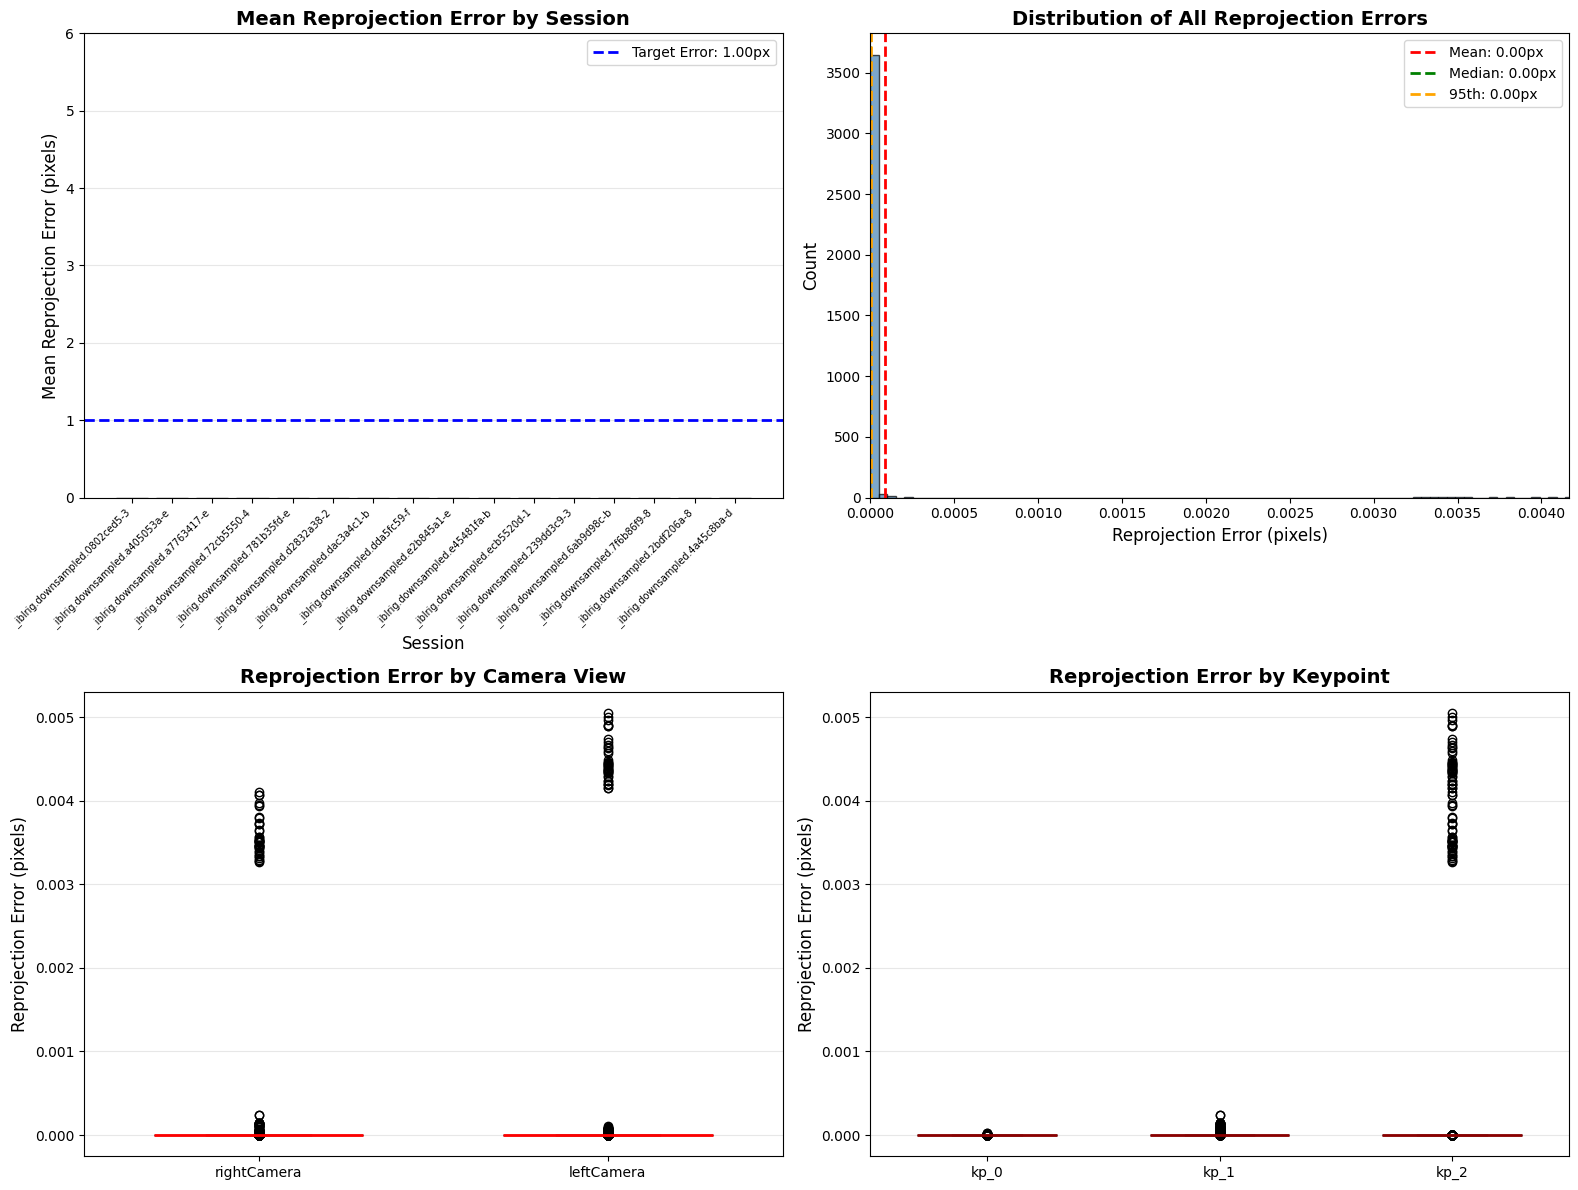


OVERALL STATISTICS (all 16 sessions, 3772 measurements)
Mean error:        0.000 pixels
Median error:      0.000 pixels
Std deviation:     0.001 pixels
95th percentile:   0.000 pixels
99th percentile:   0.004 pixels
Max error:         0.005 pixels


In [28]:
# Cell: Summary Statistics Across All Sessions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- MODIFIED: 1. Mean error per session (bar plot) ---
ax = axes[0, 0]
session_names = list(session_results.keys())
mean_errors = [np.nanmean(session_results[s]['errors']) for s in session_names]
# Set colors based on comparison to the *fixed target* of 1.0 (or keep original median logic if needed elsewhere)
colors = ['red' if err > 1.0 else 'green' for err in mean_errors] 
ax.bar(range(len(session_names)), mean_errors, color=colors, edgecolor='black', alpha=0.7)

# FIXED: Set the horizontal line at y=1.0 and update the label
FIXED_TARGET_ERROR = 1.0
ax.axhline(FIXED_TARGET_ERROR, color='blue', linestyle='--', linewidth=2, 
           label=f'Target Error: {FIXED_TARGET_ERROR:.2f}px')

# NEW: Set the maximum y-axis limit to 6
ax.set_ylim(0, 6) 

ax.set_xlabel('Session', fontsize=12)
ax.set_ylabel('Mean Reprojection Error (pixels)', fontsize=12)
ax.set_title('Mean Reprojection Error by Session', fontsize=14, weight='bold')
ax.set_xticks(range(len(session_names)))
ax.set_xticklabels([s[:30] for s in session_names], rotation=45, ha='right', fontsize=7)
ax.grid(axis='y', alpha=0.3)
ax.legend()
# ------------------------------------------------------


# 2. Distribution of errors across all sessions (Unchanged)
ax = axes[0, 1]
all_errors = np.concatenate([session_results[s]['errors'].flatten() 
                             for s in session_names])
all_errors = all_errors[~np.isnan(all_errors)]
ax.hist(all_errors, bins=100, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(np.mean(all_errors), color='r', linestyle='--', linewidth=2, 
           label=f'Mean: {np.mean(all_errors):.2f}px')
ax.axvline(np.median(all_errors), color='g', linestyle='--', linewidth=2,
           label=f'Median: {np.median(all_errors):.2f}px')
ax.axvline(np.percentile(all_errors, 95), color='orange', linestyle='--', linewidth=2,
           label=f'95th: {np.percentile(all_errors, 95):.2f}px')
ax.set_xlabel('Reprojection Error (pixels)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Distribution of All Reprojection Errors', fontsize=14, weight='bold')
ax.legend(fontsize=10)
ax.set_xlim(0, np.percentile(all_errors, 99))  # Zoom in to 99th percentile

# 3. Error by camera view (across all sessions) (Unchanged)
ax = axes[1, 0]
view_errors = []
for view_idx in range(n_views):
    view_err = np.concatenate([session_results[s]['errors'][:, view_idx, :].flatten() 
                               for s in session_names])
    view_err = view_err[~np.isnan(view_err)]
    view_errors.append(view_err)

bp = ax.boxplot(view_errors, labels=cam_names, patch_artist=True, widths=0.6)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
for median in bp['medians']:
    median.set_color('red')
    median.set_linewidth(2)
ax.set_ylabel('Reprojection Error (pixels)', fontsize=12)
ax.set_title('Reprojection Error by Camera View', fontsize=14, weight='bold')
ax.grid(axis='y', alpha=0.3)

# 4. Error by keypoint (across all sessions) (Unchanged)
ax = axes[1, 1]
keypoint_names = data_info.get('keypoint_names', [f'kp_{i}' for i in range(n_keypoints)])
kp_errors = []
for kp_idx in range(n_keypoints):
    kp_err = np.concatenate([session_results[s]['errors'][:, :, kp_idx].flatten() 
                             for s in session_names])
    kp_err = kp_err[~np.isnan(kp_err)]
    kp_errors.append(kp_err)

bp = ax.boxplot(kp_errors, labels=keypoint_names[:n_keypoints], patch_artist=True, widths=0.6)
for patch in bp['boxes']:
    patch.set_facecolor('lightcoral')
for median in bp['medians']:
    median.set_color('darkred')
    median.set_linewidth(2)
ax.set_ylabel('Reprojection Error (pixels)', fontsize=12)
ax.set_title('Reprojection Error by Keypoint', fontsize=14, weight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics (Unchanged)
print(f"\n{'='*80}")
print(f"OVERALL STATISTICS (all {len(session_names)} sessions, {len(all_errors)} measurements)")
print(f"{'='*80}")
print(f"Mean error:        {np.mean(all_errors):.3f} pixels")
print(f"Median error:      {np.median(all_errors):.3f} pixels")
print(f"Std deviation:     {np.std(all_errors):.3f} pixels")
print(f"95th percentile:   {np.percentile(all_errors, 95):.3f} pixels")
print(f"99th percentile:   {np.percentile(all_errors, 99):.3f} pixels")
print(f"Max error:         {np.max(all_errors):.3f} pixels")

img_path: labeled_data/_iblrig_rightCamera.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd/img00061861.jpg
img_path: labeled_data/_iblrig_leftCamera.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd/img00061861.jpg


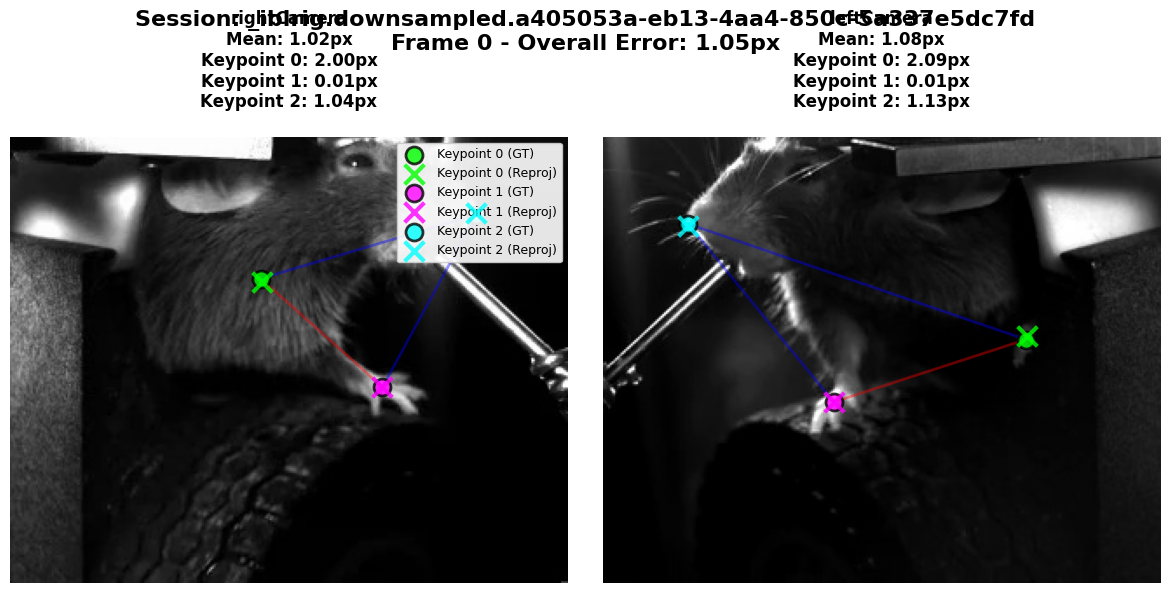

In [29]:
# Cell: Visualize Individual Session Reprojections (Color per Keypoint)
def visualize_session_reprojection(session_name, frame_idx=0, save_path=None):
    """Visualize reprojection for a specific session and frame with color per keypoint."""
    
    if session_name not in session_results:
        print(f"Session '{session_name}' not found!")
        print(f"Available sessions: {list(session_results.keys())[:5]}...")
        return
    
    data = session_results[session_name]
    keypoints_2d = data['keypoints_2d']
    keypoints_2d_reproj = data['keypoints_2d_reproj']
    image_paths = data['image_paths']
    errors = data['errors']
    
    n_views = len(cam_names)
    if n_views == 2:
        rows, cols = 1, 2
    elif n_views == 6:
        rows, cols = 2, 3
    else:
        rows = int(np.ceil(np.sqrt(n_views)))
        cols = int(np.ceil(n_views / rows))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*6, rows*6))
    if n_views == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    # Define colors for each keypoint
    keypoint_colors = ['lime', 'magenta', 'cyan', 'yellow', 'orange', 'red', 'blue', 'green']
    # Get keypoint names if available
    keypoint_names = data_info.get('keypoint_names', [f'Keypoint {i}' for i in range(n_keypoints)])
    
    for view_idx in range(n_views):
        ax = axes[view_idx]
        
        # Load image
        img_path = image_paths[view_idx][frame_idx]
        if not Path(img_path).is_absolute():
            # img_path = data_dir / img_path
            print(f"img_path: {img_path}")
            img_path = os.path.join(data_dir, img_path)
        
        try:
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                ax.imshow(img, cmap='gray')
        except:
            pass
        
        # Get keypoints for this view
        kpts_orig = keypoints_2d[frame_idx, view_idx]  # (n_keypoints, 2)
        kpts_reproj = keypoints_2d_reproj[frame_idx, view_idx]  # (n_keypoints, 2)
        
        # Plot each keypoint with its own color
        for kp_idx in range(n_keypoints):
            color = keypoint_colors[kp_idx % len(keypoint_colors)]
            kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
            
            # Original keypoint (circle 'o')
            if not np.isnan(kpts_orig[kp_idx]).any():
                ax.scatter(kpts_orig[kp_idx, 0], kpts_orig[kp_idx, 1],
                          color=color, s=150, marker='o', edgecolors='black',
                          linewidths=2, label=f'{kp_name} (GT)', zorder=5, alpha=0.8)
            
            # Reprojected keypoint (X marker)
            if not np.isnan(kpts_reproj[kp_idx]).any():
                ax.scatter(kpts_reproj[kp_idx, 0], kpts_reproj[kp_idx, 1],
                          color=color, s=200, marker='x', linewidths=3,
                          label=f'{kp_name} (Reproj)', zorder=6, alpha=0.8)
            
            # Draw error line between original and reprojected
            if not np.isnan(kpts_orig[kp_idx]).any() and not np.isnan(kpts_reproj[kp_idx]).any():
                ax.plot([kpts_orig[kp_idx, 0], kpts_reproj[kp_idx, 0]],
                       [kpts_orig[kp_idx, 1], kpts_reproj[kp_idx, 1]],
                       color=color, linewidth=2, alpha=0.5, linestyle='--', zorder=4)
        
        # Draw skeleton on original points (if available)
        if skeleton is not None and len(skeleton) > 0 and skeleton_colors is not None:
            valid_orig = ~np.isnan(kpts_orig).any(axis=1)
            for l, limb in enumerate(skeleton):
                if len(limb) == 2 and valid_orig[limb[0]] and valid_orig[limb[1]]:
                    ax.plot(kpts_orig[limb, 0], kpts_orig[limb, 1],
                           skeleton_colors[l], linewidth=2, alpha=0.4, zorder=3)
        
        # Calculate and display error
        view_error = errors[frame_idx, view_idx, :]
        mean_error = np.nanmean(view_error)
        
        # Show per-keypoint errors
        error_text = f'{cam_names[view_idx]}\nMean: {mean_error:.2f}px\n'
        for kp_idx in range(n_keypoints):
            kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
            kp_error = view_error[kp_idx]
            if not np.isnan(kp_error):
                error_text += f'{kp_name}: {kp_error:.2f}px\n'
        
        ax.set_title(error_text, fontsize=12, weight='bold')
        ax.axis('off')
        
        if view_idx == 0:
            ax.legend(loc='upper right', fontsize=9, framealpha=0.9, ncol=1)
    
    # Hide unused subplots
    for i in range(n_views, len(axes)):
        axes[i].axis('off')
    
    overall_error = np.nanmean(errors[frame_idx])
    plt.suptitle(f'Session: {session_name}\nFrame {frame_idx} - Overall Error: {overall_error:.2f}px', 
                fontsize=16, weight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    
    plt.show()

# Visualize

# Visualize the session you wanted
# Visualize the first session
# first_session = list(session_results.keys())[0]
# print(f"Visualizing first session: {first_session}\n")
visualize_session_reprojection("_iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd", frame_idx=0)
# visualize_session_reprojection("_iblrig.downsampled.781b35fd-e1f0-4d14-b2bb-95b7263082bb", frame_idx=19)
# visualize_session_reprojection("_iblrig.downsampled.15b69921-d471-4ded-8814-2adad954bcd8", frame_idx=12)

# Creating CollectedData which is actually the reprojections 

In [30]:
# Cell: Create Reprojected CSV Files (Using Original CSV Labels Directly)
import pandas as pd
import numpy as np
from pathlib import Path

def create_reprojected_csv_with_original_labels(output_dir):
    """
    Create reprojected CSV files by:
    1. Loading original labels directly from CSV
    2. Getting reprojections from session_results
    3. Using reprojection if available, else original label, else NaN
    """
    
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    
    print(f"\n{'='*80}")
    print(f"Creating reprojected CSV files (using original labels directly)")
    print(f"Output directory: {output_dir}")
    print(f"{'='*80}\n")
    
    # Get keypoint names
    keypoint_names = cfg.data.keypoint_names
    n_kps = len(keypoint_names)
    
    print(f"Keypoints ({n_kps}): {keypoint_names}")
    print(f"Views: {cam_names}\n")
    
    # Process each view
    for view_idx, cam_name in enumerate(cam_names):
        print(f"\n{'='*80}")
        print(f"Processing {cam_name}")
        print(f"{'='*80}")
        
        # Load ORIGINAL CSV for this view
        # original_csv = data_dir / cfg.data.csv_file[view_idx]
        original_csv = f"/teamspace/studios/data/ibl-mouse/CollectedData_{cam_name}.csv"
        original_df = pd.read_csv(original_csv, header=[0, 1, 2], index_col=0)
        scorer_name = original_df.columns.levels[0][0]
        
        # print(f"Loaded original CSV: {original_csv.name}")
        print(f"  Scorer: {scorer_name}")
        print(f"  Images: {len(original_df)}")
        
        # Create a mapping from image path to reprojected coordinates
        reproj_map = {}
        
        for session_name, data in session_results.items():
            keypoints_2d_reproj = data['keypoints_2d_reproj']  # (n_frames, n_views, n_keypoints, 2)
            image_paths = data['image_paths'][view_idx]
            
            n_frames = keypoints_2d_reproj.shape[0]
            
            for frame_idx in range(n_frames):
                img_path = image_paths[frame_idx]
                
                if img_path.startswith('missing_frame_'):
                    continue
                
                # Store reprojections for this image
                reproj_coords = keypoints_2d_reproj[frame_idx, view_idx, :, :]  # (n_keypoints, 2)
                reproj_map[img_path] = reproj_coords
        
        print(f"Built reprojection map: {len(reproj_map)} images")
        
        # Now combine: for each image in original CSV, use reproj if available, else original
        output_data = []
        stats = {
            'total': 0,
            'used_reprojection': 0,
            'used_original': 0,
            'remained_nan': 0
        }
        
        for img_path in original_df.index:
            row = [img_path]
            
            # Get original labels for this image
            original_row = original_df.loc[img_path]
            
            # Get reprojections if available
            reproj_coords = reproj_map.get(img_path, None)
            
            # For each keypoint
            for kp_idx, kp_name in enumerate(keypoint_names):
                # Get original x, y
                orig_x = original_row[(scorer_name, kp_name, 'x')]
                orig_y = original_row[(scorer_name, kp_name, 'y')]
                
                # Get reprojection x, y (if available)
                if reproj_coords is not None:
                    reproj_x = reproj_coords[kp_idx, 0]
                    reproj_y = reproj_coords[kp_idx, 1]
                else:
                    reproj_x = np.nan
                    reproj_y = np.nan
                
                # Decide what to use for x
                if not np.isnan(reproj_x):
                    final_x = reproj_x
                    stats['used_reprojection'] += 1
                elif not np.isnan(orig_x):
                    final_x = orig_x
                    stats['used_original'] += 1
                else:
                    final_x = np.nan
                    stats['remained_nan'] += 1
                
                # Decide what to use for y
                if not np.isnan(reproj_y):
                    final_y = reproj_y
                    stats['used_reprojection'] += 1
                elif not np.isnan(orig_y):
                    final_y = orig_y
                    stats['used_original'] += 1
                else:
                    final_y = np.nan
                    stats['remained_nan'] += 1
                
                stats['total'] += 2
                
                row.append(final_x)
                row.append(final_y)
            
            output_data.append(row)
        
        print(f"\nProcessed {len(output_data)} images")
        print(f"Total coordinate values: {stats['total']}")
        print(f"  Used reprojection:  {stats['used_reprojection']} ({100*stats['used_reprojection']/stats['total']:.1f}%)")
        print(f"  Used original (FB): {stats['used_original']} ({100*stats['used_original']/stats['total']:.1f}%)")
        print(f"  Remained NaN:       {stats['remained_nan']} ({100*stats['remained_nan']/stats['total']:.1f}%)")
        
        # Write CSV
        output_path = output_dir / f'CollectedData_{cam_name}_reprojected.csv'
        
        with open(output_path, 'w') as f:
            # Header row 1: scorer
            scorer_row = ['scorer'] * (n_kps * 2 + 1)
            f.write(','.join(scorer_row) + '\n')
            
            # Header row 2: bodyparts
            bodyparts_row = ['bodyparts']
            for kp_name in keypoint_names:
                bodyparts_row.extend([kp_name, kp_name])
            f.write(','.join(bodyparts_row) + '\n')
            
            # Header row 3: coords
            coords_row = ['coords']
            for _ in keypoint_names:
                coords_row.extend(['x', 'y'])
            f.write(','.join(coords_row) + '\n')
            
            # Data rows
            for row in output_data:
                row_str = [str(row[0])]  # Image path
                for val in row[1:]:
                    if isinstance(val, float) and np.isnan(val):
                        row_str.append('')
                    else:
                        row_str.append(str(val))
                f.write(','.join(row_str) + '\n')
        
        print(f"\n✅ Saved: {output_path}")
    
    print(f"\n{'='*80}")
    print(f"✅ Completed")
    print(f"{'='*80}\n")


# Create the files
output_dir = Path('/teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files')
create_reprojected_csv_with_original_labels(output_dir)


Creating reprojected CSV files (using original labels directly)
Output directory: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files

Keypoints (3): ['pawL', 'pawR', 'nose']
Views: ['rightCamera', 'leftCamera']


Processing rightCamera
  Scorer: scorer
  Images: 640
Built reprojection map: 640 images

Processed 640 images
Total coordinate values: 3840
  Used reprojection:  3772 (98.2%)
  Used original (FB): 30 (0.8%)
  Remained NaN:       38 (1.0%)

✅ Saved: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files/CollectedData_rightCamera_reprojected.csv

Processing leftCamera
  Scorer: scorer
  Images: 640
Built reprojection map: 640 images

Processed 640 images
Total coordinate values: 3840
  Used reprojection:  3772 (98.2%)
  Used original (FB): 34 (0.9%)
  Remained NaN:       34 (0.9%)

✅ Saved: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files/CollectedData_leftCamera_reprojected.csv

✅ Completed



In [31]:
# # Cell: Create Reprojected CSV Files (Correct Format)
# import pandas as pd
# import numpy as np
# from pathlib import Path

# def create_reprojected_csv_files_correct(output_dir):
#     """
#     Create CSV files with reprojected coordinates in the EXACT format as original CollectedData files.
    
#     Args:
#         output_dir: Directory to save the reprojected CSV files
#     """
    
#     output_dir = Path(output_dir)
#     output_dir.mkdir(parents=True, exist_ok=True)
    
#     print(f"\n{'='*80}")
#     print(f"Creating reprojected CSV files (correct format)")
#     print(f"Output directory: {output_dir}")
#     print(f"{'='*80}\n")
    
#     # Load original CSV to get the scorer name
#     print("Reading original CSV to get scorer name...")
#     original_csv = data_dir / cfg.data.csv_file[0]
    
#     # Read just the first line to get scorer
#     with open(original_csv, 'r') as f:
#         first_line = f.readline().strip()
#     scorer_name = first_line.split(',')[1]  # Get the scorer name
#     print(f"  Scorer name: {scorer_name}")
    
#     # Get keypoint names from config
#     keypoint_names = cfg.data.keypoint_names
#     print(f"  Keypoints: {keypoint_names}")
#     print(f"  Views: {cam_names}")
    
#     # Create a CSV for each view
#     for view_idx, cam_name in enumerate(cam_names):
#         print(f"\nCreating CSV for {cam_name}...")
        
#         # Collect all data for this view across all sessions
#         all_image_paths = []
#         all_reprojections = []
        
#         for session_name, data in session_results.items():
#             image_paths = data['image_paths'][view_idx]
#             keypoints_2d_reproj = data['keypoints_2d_reproj']  # (n_frames, n_views, n_keypoints, 2)
            
#             n_frames = keypoints_2d_reproj.shape[0]
            
#             for frame_idx in range(n_frames):
#                 img_path = image_paths[frame_idx]
                
#                 # Skip placeholder paths
#                 if img_path.startswith('missing_frame_'):
#                     continue
                
#                 all_image_paths.append(img_path)
                
#                 # Get reprojections for this view: (n_keypoints, 2)
#                 reproj_coords = keypoints_2d_reproj[frame_idx, view_idx, :, :]
#                 all_reprojections.append(reproj_coords)
        
#         # Convert to numpy array
#         all_reprojections = np.array(all_reprojections)  # (n_images, n_keypoints, 2)
        
#         print(f"  Collected {len(all_image_paths)} images")
        
#         # Build the data rows (one row per image)
#         data_rows = []
#         for img_idx in range(len(all_image_paths)):
#             row = [all_image_paths[img_idx]]
#             for kp_idx in range(len(keypoint_names)):
#                 row.append(all_reprojections[img_idx, kp_idx, 0])  # x
#                 row.append(all_reprojections[img_idx, kp_idx, 1])  # y
#             data_rows.append(row)
        
#         # Write CSV manually to get exact format
#         output_path = output_dir / f'CollectedData_{cam_name}_reprojected.csv'
        
#         with open(output_path, 'w') as f:
#             # Header row 1: scorer names
#             scorer_row = ['scorer'] * (len(keypoint_names) * 2 + 1)
#             f.write(','.join(scorer_row) + '\n')
            
#             # Header row 2: bodyparts (keypoint names repeated twice each)
#             bodyparts_row = ['bodyparts']
#             for kp_name in keypoint_names:
#                 bodyparts_row.extend([kp_name, kp_name])
#             f.write(','.join(bodyparts_row) + '\n')
            
#             # Header row 3: coords (x, y alternating)
#             coords_row = ['coords']
#             for _ in keypoint_names:
#                 coords_row.extend(['x', 'y'])
#             f.write(','.join(coords_row) + '\n')
            
#             # Data rows
#             for row in data_rows:
#                 # Convert numbers to strings, keep NaN as empty or 'nan'
#                 row_str = [str(row[0])]  # Image path
#                 for val in row[1:]:
#                     if np.isnan(val):
#                         row_str.append('')  # Empty string for NaN
#                     else:
#                         row_str.append(str(val))
#                 f.write(','.join(row_str) + '\n')
        
#         print(f"  ✅ Saved: {output_path}")
#         print(f"     Images: {len(all_image_paths)}")
#         print(f"     Keypoints: {len(keypoint_names)}")
#         print(f"     Columns: {len(keypoint_names) * 2} (x,y pairs)")
    
#     print(f"\n{'='*80}")
#     print(f"✅ Created {len(cam_names)} reprojected CSV files in correct format")
#     print(f"{'='*80}\n")


# # Create the reprojected CSV files
# output_dir = Path('/teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files')
# create_reprojected_csv_files_correct(output_dir)

# Creating a video for all of the frames 

In [39]:
# Cell: Revised Video Creation Function for Robustness and KeyError Fix

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from tqdm import tqdm
import shutil
from matplotlib.backends.backend_agg import FigureCanvasAgg as FigureCanvas

# --- Helper Function: Plotting a Single Frame ---

def plot_single_frame(frame_idx, session_name, data, n_views, n_keypoints, cam_names, data_dir, 
                      keypoint_colors, keypoint_names, rows, cols, skeleton, skeleton_colors, dpi):
    """Generates the Matplotlib figure for a single frame."""
    
    keypoints_2d = data['keypoints_2d']
    keypoints_2d_reproj = data['keypoints_2d_reproj']
    image_paths = data['image_paths']
    errors = data['errors']
    n_frames = keypoints_2d.shape[0]

    # Initialize figure
    fig, axes = plt.subplots(rows, cols, figsize=(cols*6, rows*6), dpi=dpi)
    if n_views == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    images_loaded = False
    default_height, default_width = 800, 1000 # Fallback size

    for view_idx in range(n_views):
        ax = axes[view_idx]
        img = None
        
        # --- Image Loading Logic ---
        img_path = image_paths[view_idx][frame_idx]
        
        if not img_path.startswith('missing_frame_'):
            # NOTE: data_dir MUST be defined globally for this to work
            # full_img_path = data_dir / img_path if not Path(img_path).is_absolute() else Path(img_path)
            full_img_path = Path(os.path.join(data_dir, img_path)) if not os.path.isabs(img_path) else Path(img_path)
            try:
                img = cv2.imread(str(full_img_path), cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    ax.imshow(img, cmap='gray')
                    images_loaded = True
                    default_height, default_width = img.shape[:2] # Update fallback size
            except Exception:
                pass # Image failed to load
        
        # Set background if image failed to load (crucial for NaNs to be visible)
        if img is None:
            placeholder_img = np.ones((default_height, default_width), dtype=np.uint8) * 255
            ax.imshow(placeholder_img, cmap='gray')
            ax.text(default_width/2, default_height/2, 'Image Not Loaded',
                    color='red', fontsize=20, ha='center', va='center')

        # --- Keypoint and Reprojection Plotting ---
        kpts_orig = keypoints_2d[frame_idx, view_idx]
        kpts_reproj = keypoints_2d_reproj[frame_idx, view_idx]
        
        for kp_idx in range(n_keypoints):
            color = keypoint_colors[kp_idx % len(keypoint_colors)]
            
            # Original keypoint (circle 'o')
            if not np.isnan(kpts_orig[kp_idx]).any():
                ax.scatter(kpts_orig[kp_idx, 0], kpts_orig[kp_idx, 1],
                          color=color, s=150, marker='o', edgecolors='black',
                          linewidths=2, zorder=5, alpha=0.8)
            
            # Reprojected keypoint (X marker)
            if not np.isnan(kpts_reproj[kp_idx]).any():
                ax.scatter(kpts_reproj[kp_idx, 0], kpts_reproj[kp_idx, 1],
                          color=color, s=200, marker='x', linewidths=3,
                          zorder=6, alpha=0.8)
            
            # Draw error line (only if both are valid)
            if not np.isnan(kpts_orig[kp_idx]).any() and not np.isnan(kpts_reproj[kp_idx]).any():
                ax.plot([kpts_orig[kp_idx, 0], kpts_reproj[kp_idx, 0]],
                       [kpts_orig[kp_idx, 1], kpts_reproj[kp_idx, 1]],
                       color=color, linewidth=2, alpha=0.5, linestyle='--', zorder=4)

        # Draw skeleton
        # NOTE: skeleton and skeleton_colors MUST be defined globally for this to work
        if skeleton is not None and len(skeleton) > 0 and skeleton_colors is not None:
            valid_orig = ~np.isnan(kpts_orig).any(axis=1)
            for l, limb in enumerate(skeleton):
                if len(limb) == 2 and valid_orig[limb[0]] and valid_orig[limb[1]]:
                    ax.plot(kpts_orig[limb, 0], kpts_orig[limb, 1],
                           skeleton_colors[l], linewidth=2, alpha=0.4, zorder=3)
        
        # Calculate and display error
        view_error = errors[frame_idx, view_idx, :]
        mean_error = np.nanmean(view_error)
        
        error_text = f'{cam_names[view_idx]}\n'
        error_text += f'Mean: {mean_error:.2f}px\n' if not np.isnan(mean_error) else 'Mean: N/A\n'
        for kp_idx in range(n_keypoints):
            kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
            kp_error = view_error[kp_idx]
            error_text += f'{kp_name}: {kp_error:.2f}px\n' if not np.isnan(kp_error) else f'{kp_name}: N/A\n'
        
        ax.set_title(error_text, fontsize=12, weight='bold')
        ax.axis('off')
    
    # Final plot setup
    for i in range(n_views, len(axes)):
        axes[i].axis('off')
    
    # Legend setup
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markeredgecolor='black', markersize=10, linewidth=0, label='O = Labeled'),
        Line2D([0], [0], marker='x', color='w', markerfacecolor='gray', markeredgewidth=2, markersize=10, linewidth=0, label='X = Reprojection'),
        Line2D([0], [0], color='white', linewidth=0, label='')
    ]
    for kp_idx in range(n_keypoints):
        color = keypoint_colors[kp_idx % len(keypoint_colors)]
        kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
        legend_elements.append(Patch(facecolor=color, edgecolor='black', label=kp_name))
    
    axes[0].legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.95, ncol=1, bbox_to_anchor=(0, 1), borderaxespad=0)
    
    img_filename = Path(image_paths[0][frame_idx]).name if not image_paths[0][frame_idx].startswith('missing_frame_') else 'Missing'
    overall_error = np.nanmean(errors[frame_idx])
    session_display = session_name[:60] + '...' if len(session_name) > 60 else session_name
    
    title_text = f'Session: {session_display}\nImage: {img_filename} | Frame: {frame_idx+1}/{n_frames}'
    title_text += f' | Overall Error: {overall_error:.2f}px' if not np.isnan(overall_error) else f' | Overall Error: N/A'
    if not images_loaded:
        title_text += '\n⚠️ WARNING: Some background images failed to load'
    
    plt.suptitle(title_text, fontsize=14, weight='bold')
    plt.tight_layout()
    
    return fig

# --- Main Function: Create Reprojection Video (V2 with Fix) ---

def create_reprojection_video_v2(output_video_path, session_names=None, fps=5, dpi=100):
    """
    Creates a single video using in-memory buffering for speed and reliability,
    and includes a robust check for n_keypoints to fix the KeyError.
    """
    
    # --- Setup and Validation ---
    if session_names is None:
        # NOTE: session_results MUST be defined globally
        session_names = list(session_results.keys())
    elif isinstance(session_names, str):
        session_names = [session_names]
    
    valid_sessions = [s for s in session_names if s in session_results]
    if len(valid_sessions) == 0:
        print(f"No valid sessions found!")
        return
    
    # NOTE: cam_names MUST be defined globally
    n_views = len(cam_names)
    
    # --- KEY ERROR FIX: Get n_keypoints robustly ---
    first_session_key = valid_sessions[0]
    try:
        # NOTE: data_info MUST be defined globally
        n_keypoints = data_info['n_keypoints']
    except KeyError:
        # Fallback: Get n_keypoints from the shape of the 2D keypoint data
        # Shape is usually (frames, views, keypoints, coordinates)
        n_keypoints = session_results[first_session_key]['keypoints_2d'].shape[2]
        print(f"Warning: 'n_keypoints' missing from data_info. Derived value: {n_keypoints}")

    # Setup subplot layout
    rows, cols = (1, 2) if n_views == 2 else ((2, 3) if n_views == 6 else (int(np.ceil(np.sqrt(n_views))), int(np.ceil(n_views / int(np.ceil(np.sqrt(n_views)))))))
    
    # NOTE: data_info MUST be defined globally
    keypoint_colors = ['lime', 'magenta', 'cyan', 'yellow', 'orange', 'red', 'blue', 'green', 
                       'purple', 'pink', 'brown', 'gray', 'olive', 'navy', 'teal', 'maroon']
    keypoint_names = data_info.get('keypoint_names', [f'Keypoint {i}' for i in range(n_keypoints)])
    
    total_frames = sum(session_results[s]['keypoints_2d'].shape[0] for s in valid_sessions)
    print(f"\n{'='*80}")
    print(f"Creating video with {len(valid_sessions)} sessions, {total_frames} total frames")
    print(f"Output: {output_video_path}")
    print(f"{'='*80}\n")
    
    # --- Video Initialization ---
    
    # 1. Plot a dummy frame to get the exact final dimensions
    dummy_fig = plot_single_frame(0, first_session_key, session_results[first_session_key], n_views, n_keypoints, 
                                  cam_names, data_dir, keypoint_colors, keypoint_names, rows, cols, skeleton, skeleton_colors, dpi)
    
    canvas = FigureCanvas(dummy_fig)
    canvas.draw()
    buffer = np.asarray(canvas.buffer_rgba())
    height, width, _ = buffer.shape
    plt.close(dummy_fig)
    
    print(f"Video dimensions determined: {width}x{height} pixels at {dpi} DPI.")

    # Initialize Video Writer
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(str(output_video_path), fourcc, fps, (width, height))
    
    if not out.isOpened():
        print(f"ERROR: Could not open video writer for {output_video_path}")
        return

    # --- Frame Processing and Writing ---
    frame_counter = 0
    
    with tqdm(total=total_frames, desc="Generating and Writing Frames") as pbar:
        for session_name in valid_sessions:
            data = session_results[session_name]
            n_frames = data['keypoints_2d'].shape[0]
            
            for frame_idx in range(n_frames):
                fig = plot_single_frame(frame_idx, session_name, data, n_views, n_keypoints, cam_names, data_dir, 
                                        keypoint_colors, keypoint_names, rows, cols, skeleton, skeleton_colors, dpi)
                
                # Convert Matplotlib figure to OpenCV BGR image (in memory)
                canvas = FigureCanvas(fig)
                canvas.draw()
                
                # Get buffer as RGBA (H, W, 4)
                buffer = np.asarray(canvas.buffer_rgba())
                
                # Convert RGBA to BGR
                frame_rgb = buffer[:, :, :3]  # Drop alpha channel
                frame_bgr = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR)
                
                # Write the frame
                out.write(frame_bgr)
                plt.close(fig)
                
                frame_counter += 1
                pbar.update(1)

    out.release()
    
    # --- Final Summary ---
    print(f"\n{'='*80}")
    print(f"✅ Video created successfully!")
    print(f"   Video path: {output_video_path}")
    print(f"   Total frames: {frame_counter}")
    print(f"   Duration: {frame_counter/fps:.1f} seconds")
    print(f"{'='*80}\n")
    
    return

# --- Execution Block (requires defining global variables) ---

# NOTE: The following variables must be defined in your environment before running:
# - session_results (dictionary of session data)
# - cam_names (list of camera/view names)
# - data_info (dictionary containing keypoint names, etc.)
# - data_dir (Path object pointing to the root data directory)
# - skeleton (list of tuples for drawing limbs)
# - skeleton_colors (list of colors for limbs)

# Example of how you would call it:
output_dir = Path('/teamspace/studios/this_studio/outputs/ibl-mouse/reprojection_videos')
output_dir.mkdir(parents=True, exist_ok=True)

print("Creating video for all sessions using V2 (in-memory) method...")
create_reprojection_video_v2(
    output_video_path=output_dir / 'all_sessions_reprojections_OOD_data.mp4',
    session_names=None,
    fps=5,
    dpi=100
)

# session_name = '_iblrig.downsampled.781b35fd-e1f0-4d14-b2bb-95b7263082bb'
# create_reprojection_video_v2(
#     output_video_path=os.path.join(output_dir, f'reprojections_{session_name}_update_label.mp4'),
#     session_names=session_name,
#     fps=5,
#     dpi=100
# )

Creating video for all sessions using V2 (in-memory) method...

Creating video with 8 sessions, 320 total frames
Output: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojection_videos/all_sessions_reprojections_OOD_data.mp4

Video dimensions determined: 1200x600 pixels at 100 DPI.


Generating and Writing Frames: 100%|██████████| 320/320 [02:51<00:00,  1.86it/s]


✅ Video created successfully!
   Video path: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojection_videos/all_sessions_reprojections_OOD_data.mp4
   Total frames: 320
   Duration: 64.0 seconds



# creating a file that is basically CollectedData but with reprojections


Creating reprojected CSV files (correct format)
Output directory: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files

Reading original CSV to get scorer name...
  Scorer name: scorer
  Keypoints: ['pawL', 'pawR', 'nose']
  Views: ['rightCamera', 'leftCamera']

Creating CSV for rightCamera...
  Collected 800 images
  ✅ Saved: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files/CollectedData_rightCamera_reprojected.csv
     Images: 800
     Keypoints: 3
     Columns: 6 (x,y pairs)

Creating CSV for leftCamera...
  Collected 800 images
  ✅ Saved: /teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files/CollectedData_leftCamera_reprojected.csv
     Images: 800
     Keypoints: 3
     Columns: 6 (x,y pairs)

✅ Created 2 reprojected CSV files in correct format



In [33]:
# Cell: Verify Format Matches Original EXACTLY
def verify_exact_format_match(view_idx=0):
    """Verify the format matches original CSV exactly."""
    
    cam_name = cam_names[view_idx]
    original_csv = data_dir / cfg.data.csv_file[view_idx]
    reprojected_csv = Path('/teamspace/studios/this_studio/outputs/ibl-mouse/reprojected_csv_files') / f'CollectedData_{cam_name}_reprojected.csv'
    
    print(f"\n{'='*80}")
    print(f"Verifying EXACT format match for {cam_name}")
    print(f"{'='*80}\n")
    
    # Read first few lines of each file
    print("ORIGINAL CSV (first 5 lines):")
    with open(original_csv, 'r') as f:
        for i in range(5):
            line = f.readline().rstrip()
            print(f"  {i+1}: {line[:120]}{'...' if len(line) > 120 else ''}")
    
    print("\nREPROJECTED CSV (first 5 lines):")
    with open(reprojected_csv, 'r') as f:
        for i in range(5):
            line = f.readline().rstrip()
            print(f"  {i+1}: {line[:120]}{'...' if len(line) > 120 else ''}")
    
    # Check headers match
    with open(original_csv, 'r') as f:
        orig_headers = [f.readline().strip() for _ in range(3)]
    
    with open(reprojected_csv, 'r') as f:
        reproj_headers = [f.readline().strip() for _ in range(3)]
    
    print(f"\n{'='*80}")
    print("Header Comparison:")
    print(f"{'='*80}")
    
    for i, (orig, reproj) in enumerate(zip(orig_headers, reproj_headers)):
        if orig == reproj:
            print(f"✅ Row {i+1} MATCHES")
        else:
            print(f"❌ Row {i+1} DOES NOT MATCH")
            print(f"   Original:    {orig}")
            print(f"   Reprojected: {reproj}")
    
    print(f"\n{'='*80}\n")


# Verify
verify_exact_format_match(view_idx=0)
verify_exact_format_match(view_idx=1)


Verifying EXACT format match for rightCamera

ORIGINAL CSV (first 5 lines):
  1: scorer,scorer,scorer,scorer,scorer,scorer,scorer
  2: bodyparts,pawL,pawL,pawR,pawR,nose,nose
  3: coords,x,y,x,y,x,y
  4: labeled_data/_iblrig_rightCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00014526.jpg,257.931758530184,104.8...
  5: labeled_data/_iblrig_rightCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00053092.jpg,222.506142506142,154.1...

REPROJECTED CSV (first 5 lines):
  1: scorer,scorer,scorer,scorer,scorer,scorer,scorer
  2: bodyparts,pawL,pawL,pawR,pawR,nose,nose
  3: coords,x,y,x,y,x,y
  4: labeled_data/_iblrig_rightCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00014526.jpg,257.8811730617508,104....
  5: labeled_data/_iblrig_rightCamera.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c/img00053092.jpg,222.38614484845576,153...

Header Comparison:
✅ Row 1 MATCHES
✅ Row 2 MATCHES
✅ Row 3 MATCHES



Verifying EXACT format match for leftCamera

ORIGINAL CS

# 3D PCA reconstruction 

In [57]:
# Cell: Format Multi-View 2D Data for PCA
def format_multiview_2d_for_pca(session_results):
    """
    Format multi-view 2D keypoints as concatenated vectors.
    Format: [x_view0, y_view0, x_view1, y_view1, ...]
    """
    all_data = []
    metadata = []  # (session_name, frame_idx, kp_idx)
    
    for session_name, data in session_results.items():
        keypoints_2d = data['keypoints_2d']  # (n_frames, n_views, n_keypoints, 2)
        n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
        
        for frame_idx in range(n_frames):
            for kp_idx in range(n_keypoints):
                # Get this keypoint across all views
                kp_multiview = keypoints_2d[frame_idx, :, kp_idx, :]  # (n_views, 2)
                
                # Flatten to [x0, y0, x1, y1, ...]
                kp_flat = kp_multiview.flatten()  # (n_views*2,)
                
                all_data.append(kp_flat)
                metadata.append((session_name, frame_idx, kp_idx))
    
    formatted_data = np.array(all_data)
    return formatted_data, metadata


print("="*80)
print("FORMAT DATA FOR PCA")
print("="*80)

formatted_data, metadata = format_multiview_2d_for_pca(session_results)
print(f"Formatted data shape: {formatted_data.shape}")

# Remove rows with any NaN
valid_mask = ~np.isnan(formatted_data).any(axis=1)
formatted_data_clean = formatted_data[valid_mask]
metadata_clean = [metadata[i] for i in range(len(metadata)) if valid_mask[i]]

print(f"Valid samples: {valid_mask.sum()} / {len(valid_mask)}")

FORMAT DATA FOR PCA
Formatted data shape: (2400, 4)
Valid samples: 2249 / 2400


In [58]:
# Cell: Import NaNPCA
from lightning_pose.utils.pca import NaNPCA

print("Imported NaNPCA")

# Cell: Apply PCA Per Session (with NaNPCA)
print("="*80)
print("APPLYING PCA PER SESSION (using NaNPCA)")
print("="*80)

n_components = 3  # Change this to test different dimensions

for session_name, data in session_results.items():
    print(f"\n{'-'*80}")
    print(f"Session: {session_name}")
    print(f"{'-'*80}")
    
    keypoints_2d = data['keypoints_2d']  # (n_frames, n_views, n_keypoints, 2)
    n_frames, n_views, n_keypoints, _ = keypoints_2d.shape
    print(f"  Keypoints 2D shape: {keypoints_2d.shape}")
    print(f" keypoints 2d shape is (n_frames, n_views, n_keypoints, 2)")
    
    # Format data: for each frame/keypoint, concatenate all views
    # Shape: (n_frames * n_keypoints, n_views * 2)
    formatted_data = []
    for frame_idx in range(n_frames):
        for kp_idx in range(n_keypoints):
            kp_multiview = keypoints_2d[frame_idx, :, kp_idx, :]  # (n_views, 2)
            kp_flat = kp_multiview.flatten()  # (n_views*2,)
            formatted_data.append(kp_flat)
    
    formatted_data = np.array(formatted_data)  # (n_frames*n_keypoints, n_views*2)
    
    print(f"  Formatted data shape: {formatted_data.shape}")
    
    # Count NaN samples
    has_nan = np.isnan(formatted_data).any(axis=1)
    print(f"  Samples with NaN: {has_nan.sum()} / {len(has_nan)}")
    
    # Fit NaNPCA (handles NaN automatically!)
    nanpca = NaNPCA(n_components=min(n_components, n_views * 2))
    nanpca.fit(formatted_data)
    
    print(f"  Explained variance: {nanpca.explained_variance_ratio_}")
    print(f"  Cumulative: {np.cumsum(nanpca.explained_variance_ratio_)}")
    
    # Transform and reconstruct
    latent = nanpca.transform(formatted_data)
    reconstructed = nanpca.inverse_transform(latent)
    
    # Compute reconstruction error (ignoring NaN positions)
    diff = formatted_data - reconstructed
    
    # Per-sample error (RMS across all coordinates, ignoring NaN)
    error_per_sample = np.sqrt(np.nanmean(diff**2, axis=1))
    
    # Overall statistics
    mean_error = np.nanmean(error_per_sample)
    median_error = np.nanmedian(error_per_sample)
    std_error = np.nanstd(error_per_sample)
    
    print(f"\n  2D PCA Reconstruction Error:")
    print(f"    Mean: {mean_error:.3f} px")
    print(f"    Median: {median_error:.3f} px")
    print(f"    Std: {std_error:.3f} px")
    print(f"    95th percentile: {np.nanpercentile(error_per_sample, 95):.3f} px")
    
    # Store results
    data['pca_2d_model'] = nanpca
    data['pca_2d_latent'] = latent.reshape(n_frames, n_keypoints, n_components)
    data['pca_2d_reconstructed'] = reconstructed.reshape(n_frames, n_keypoints, n_views*2)
    data['pca_2d_error'] = error_per_sample.reshape(n_frames, n_keypoints)
    
    # Interpretation
    if mean_error < 2.0:
        print(f"    ✅ LOW ERROR: PCA is a good constraint")
    elif mean_error < 5.0:
        print(f"    ⚠️ MODERATE ERROR: PCA adds some distortion")
    else:
        print(f"    ❌ HIGH ERROR: PCA is too restrictive")

print(f"\n{'='*80}")
print("PCA analysis complete for all sessions!")
print(f"{'='*80}")

  error_per_sample = np.sqrt(np.nanmean(diff**2, axis=1))



Imported NaNPCA
APPLYING PCA PER SESSION (using NaNPCA)

--------------------------------------------------------------------------------
Session: _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c
--------------------------------------------------------------------------------
  Keypoints 2D shape: (40, 2, 3, 2)
 keypoints 2d shape is (n_frames, n_views, n_keypoints, 2)
  Formatted data shape: (120, 4)
  Samples with NaN: 0 / 120
  Explained variance: [0.82876227 0.13484368 0.03605445]
  Cumulative: [0.82876227 0.96360595 0.9996604 ]

  2D PCA Reconstruction Error:
    Mean: 0.492 px
    Median: 0.383 px
    Std: 0.424 px
    95th percentile: 1.301 px
    ✅ LOW ERROR: PCA is a good constraint

--------------------------------------------------------------------------------
Session: _iblrig.downsampled.a405053a-eb13-4aa4-850c-5a337e5dc7fd
--------------------------------------------------------------------------------
  Keypoints 2D shape: (40, 2, 3, 2)
 keypoints 2d shape is (n_

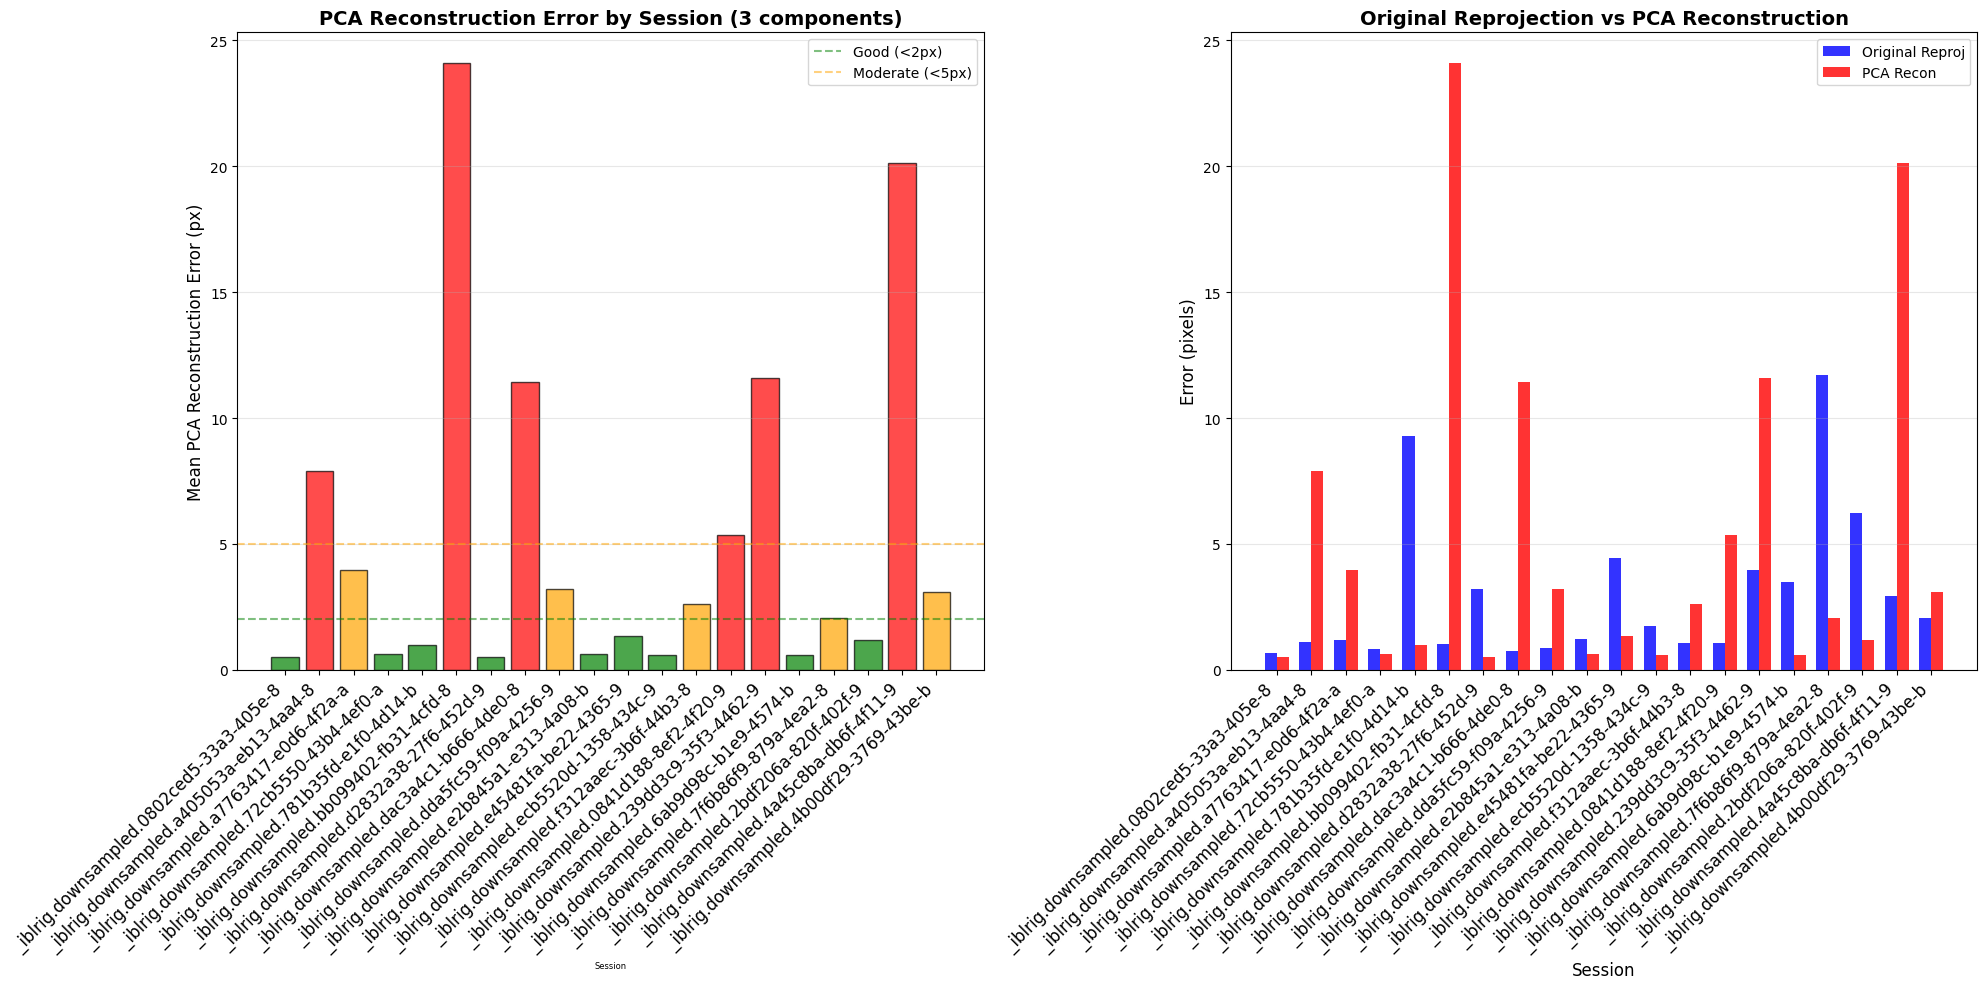


SUMMARY ACROSS ALL SESSIONS
Overall PCA reconstruction error: 2.997 ± 3.913 px
Median: 1.561 px
95th percentile: 12.413 px

Mean variance explained: 99.9%

Best session: _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c
  Error: 0.492 px

Worst session: _iblrig.downsampled.bb099402-fb31-4cfd-824e-1c97530a0875
  Error: 24.113 px


In [59]:
# Cell: Compare Sessions
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Collect statistics per session
session_names = list(session_results.keys())
session_means = []
session_medians = []
session_variances = []

for session_name in session_names:
    errors = session_results[session_name]['pca_2d_error']
    session_means.append(np.nanmean(errors))
    session_medians.append(np.nanmedian(errors))
    variance_explained = session_results[session_name]['pca_2d_model'].explained_variance_ratio_.sum()
    session_variances.append(variance_explained * 100)

# 1. Mean error per session
# ax = axes[0, 0]
ax = axes[0]
colors = ['green' if err < 2.0 else 'orange' if err < 5.0 else 'red' for err in session_means]
bars = ax.bar(range(len(session_names)), session_means, color=colors, alpha=0.7, edgecolor='black')
ax.axhline(2.0, color='green', linestyle='--', alpha=0.5, label='Good (<2px)')
ax.axhline(5.0, color='orange', linestyle='--', alpha=0.5, label='Moderate (<5px)')
ax.set_xlabel('Session', fontsize=6)
ax.set_ylabel('Mean PCA Reconstruction Error (px)', fontsize=12)
ax.set_title(f'PCA Reconstruction Error by Session ({n_components} components)', fontsize=14, weight='bold')
ax.set_xticks(range(len(session_names)))
ax.set_xticklabels([s[:40] for s in session_names], rotation=45, ha='right', fontsize=12)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 2. Distribution of all errors
# ax = axes[0, 1]
# all_errors = np.concatenate([session_results[s]['pca_2d_error'].flatten() 
#                              for s in session_names])
# all_errors = all_errors[~np.isnan(all_errors)]

# ax.hist(all_errors, bins=100, edgecolor='black', alpha=0.7, color='steelblue')
# ax.axvline(np.mean(all_errors), color='r', linestyle='--', linewidth=2,
#            label=f'Mean: {np.mean(all_errors):.2f}px')
# ax.axvline(np.median(all_errors), color='g', linestyle='--', linewidth=2,
#            label=f'Median: {np.median(all_errors):.2f}px')
# ax.set_xlabel('Reconstruction Error (pixels)', fontsize=12)
# ax.set_ylabel('Count', fontsize=12)
# ax.set_title('Distribution of All PCA Errors', fontsize=14, weight='bold')
# ax.legend()
# ax.set_xlim(0, np.percentile(all_errors, 99))

# # 3. Variance explained per session
# ax = axes[1, 0]
# ax.bar(range(len(session_names)), session_variances, alpha=0.7, color='purple', edgecolor='black')
# ax.axhline(95, color='r', linestyle='--', alpha=0.5, label='95%')
# ax.set_xlabel('Session', fontsize=12)
# ax.set_ylabel('Variance Explained (%)', fontsize=12)
# ax.set_title(f'Variance Explained by {n_components} Components', fontsize=14, weight='bold')
# ax.set_xticks(range(len(session_names)))
# ax.set_xticklabels([s[:20] for s in session_names], rotation=45, ha='right', fontsize=7)
# ax.legend()
# ax.grid(axis='y', alpha=0.3)
# ax.set_ylim(0, 100)

# 4. Comparison with original reprojection error
# ax = axes[0, 1]
ax = axes[1]
orig_errors = [np.nanmean(session_results[s]['errors']) for s in session_names]
pca_errors = session_means

x = np.arange(len(session_names))
width = 0.35
ax.bar(x - width/2, orig_errors, width, label='Original Reproj', alpha=0.8, color='blue')
ax.bar(x + width/2, pca_errors, width, label='PCA Recon', alpha=0.8, color='red')
ax.set_xlabel('Session', fontsize=12)
ax.set_ylabel('Error (pixels)', fontsize=12)
ax.set_title('Original Reprojection vs PCA Reconstruction', fontsize=14, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels([s[:40] for s in session_names], rotation=45, ha='right', fontsize=12)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("SUMMARY ACROSS ALL SESSIONS")
print("="*80)
print(f"Overall PCA reconstruction error: {np.mean(all_errors):.3f} ± {np.std(all_errors):.3f} px")
print(f"Median: {np.median(all_errors):.3f} px")
print(f"95th percentile: {np.percentile(all_errors, 95):.3f} px")
print(f"\nMean variance explained: {np.mean(session_variances):.1f}%")

# Find best and worst sessions
best_idx = np.argmin(session_means)
worst_idx = np.argmax(session_means)
print(f"\nBest session: {session_names[best_idx]}")
print(f"  Error: {session_means[best_idx]:.3f} px")
print(f"\nWorst session: {session_names[worst_idx]}")
print(f"  Error: {session_means[worst_idx]:.3f} px")

In [29]:
# Cell: Verify PCA Reconstruction (Step by Step)
print("="*80)
print("VERIFYING PCA RECONSTRUCTION LOGIC")
print("="*80)

# Pick one session as example
example_session = list(session_results.keys())[0]
data = session_results[example_session]

keypoints_2d = data['keypoints_2d']  # (n_frames, n_views, n_keypoints, 2)
n_frames, n_views, n_keypoints, _ = keypoints_2d.shape

print(f"Example session: {example_session}")
print(f"Shape: {keypoints_2d.shape}")

# Format data exactly as NaNPCA expects
formatted_data = []
for frame_idx in range(n_frames):
    for kp_idx in range(n_keypoints):
        kp_multiview = keypoints_2d[frame_idx, :, kp_idx, :]  # (n_views, 2)
        kp_flat = kp_multiview.flatten()  # (n_views*2,) = [x0, y0, x1, y1, ...]
        formatted_data.append(kp_flat)

formatted_data = np.array(formatted_data)  # (n_frames*n_keypoints, n_views*2)
print(f"\nFormatted data shape: {formatted_data.shape}")
print(f"  Each row = one keypoint instance across all views")
print(f"  Columns = [x_view0, y_view0, x_view1, y_view1, ...]")

# Step 1: Fit PCA
n_components = 3
nanpca = NaNPCA(n_components=n_components)
nanpca.fit(formatted_data)

print(f"\nStep 1: Fit PCA")
print(f"  Components shape: {nanpca.components_.shape}")  # (n_components, n_views*2)
print(f"  Mean shape: {nanpca.mean_.shape}")  # (n_views*2,)
print(f"  Explained variance: {nanpca.explained_variance_ratio_}")

# Step 2: Transform to latent space
latent = nanpca.transform(formatted_data)
print(f"\nStep 2: Transform to latent space")
print(f"  Original: {formatted_data.shape} → Latent: {latent.shape}")
print(f"  Dimensionality reduced from {formatted_data.shape[1]} to {latent.shape[1]}")

# Step 3: Reconstruct back to original space
reconstructed = nanpca.inverse_transform(latent)
print(f"\nStep 3: Reconstruct (inverse transform)")
print(f"  Latent: {latent.shape} → Reconstructed: {reconstructed.shape}")
print(f"  Back to original dimensionality")

# Step 4: Compute reconstruction error
diff = formatted_data - reconstructed
print(f"\nStep 4: Compute reconstruction error")
print(f"  This measures how well the {n_components}D PCA subspace captures the data")

# Show example
idx = 0
print(f"\nExample (sample {idx}):")
print(f"  Original:      {formatted_data[idx]}")
print(f"  Latent:        {latent[idx]}")
print(f"  Reconstructed: {reconstructed[idx]}")
print(f"  Difference:    {diff[idx]}")
print(f"  RMS error:     {np.sqrt(np.nanmean(diff[idx]**2)):.3f} px")

# Verify this is what we stored
stored_reconstructed = data['pca_2d_reconstructed'].reshape(-1, n_views*2)
print(f"\nVerification:")
print(f"  Matches stored data: {np.allclose(reconstructed, stored_reconstructed, equal_nan=True)}")

print("\n" + "="*80)
print("SUMMARY: What PCA Reconstruction Means")
print("="*80)
print("1. We concatenate multi-view 2D coordinates: [x0, y0, x1, y1, ...]")
print("2. PCA finds the principal components of this concatenated space")
print("3. We project data to low-D latent space (lossy compression)")
print("4. We reconstruct back to original space (inverse transform)")
print("5. Reconstruction error = information loss from dimensionality reduction")
print("\nThis is DIFFERENT from camera reprojection!")
print("  - No 3D involved")
print("  - No camera parameters used")
print("  - Pure linear dimensionality reduction")

VERIFYING PCA RECONSTRUCTION LOGIC
Example session: _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c
Shape: (40, 2, 3, 2)

Formatted data shape: (120, 4)
  Each row = one keypoint instance across all views
  Columns = [x_view0, y_view0, x_view1, y_view1, ...]

Step 1: Fit PCA
  Components shape: (3, 4)
  Mean shape: (4,)
  Explained variance: [0.82876227 0.13484368 0.03605445]

Step 2: Transform to latent space
  Original: (120, 4) → Latent: (120, 3)
  Dimensionality reduced from 4 to 3

Step 3: Reconstruct (inverse transform)
  Latent: (120, 3) → Reconstructed: (120, 4)
  Back to original dimensionality

Step 4: Compute reconstruction error
  This measures how well the 3D PCA subspace captures the data

Example (sample 0):
  Original:      [257.93175853 104.81889764  76.8503937  106.49868766]
  Latent:        [-58.54240711   7.31409696   4.72721765]
  Reconstructed: [257.97862855 104.95185298  76.89608938 106.36387779]
  Difference:    [-0.04687002 -0.13295534 -0.04569568  0.1

Visualizing GOOD session: _iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c


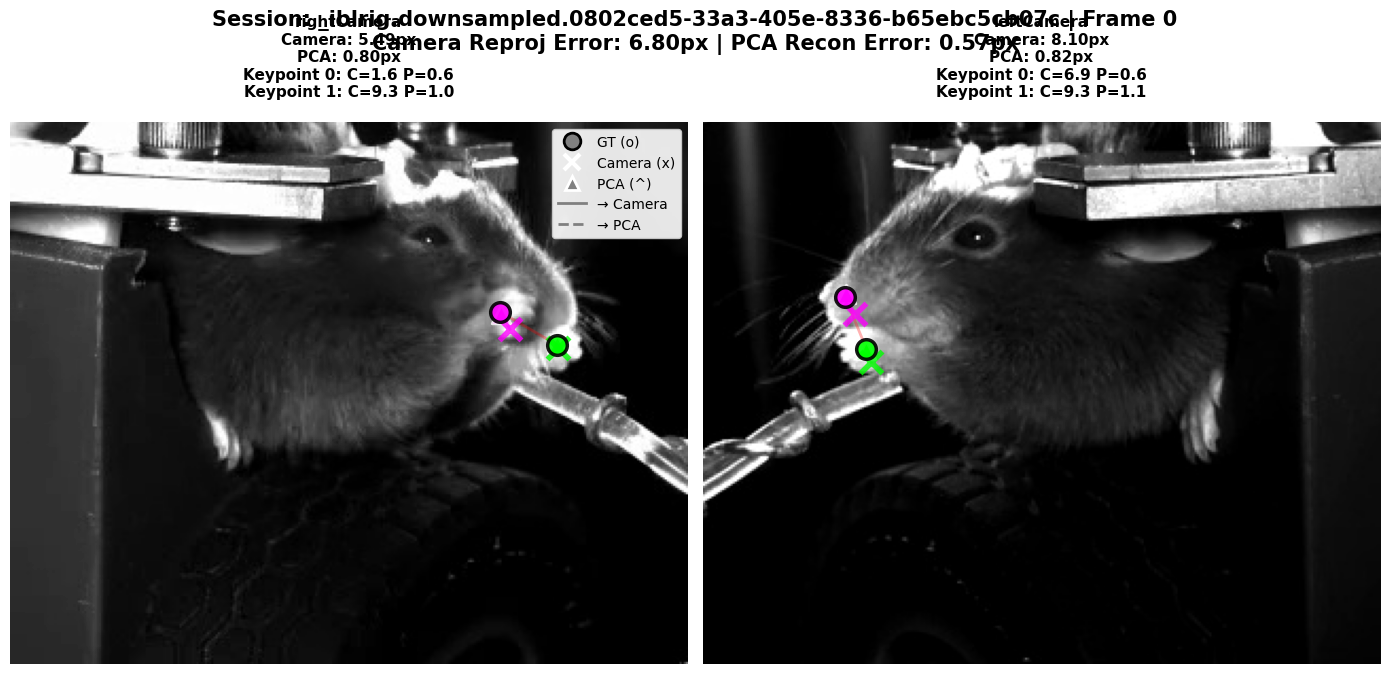


INTERPRETATION:
Camera reproj error: 6.80px
  ❌ Poor camera calibration

PCA recon error: 0.57px
  ✅ PCA is a good constraint

→ Camera calibration is the main issue (+6.22px)


Visualizing BAD session: _iblrig.downsampled.bb099402-fb31-4cfd-824e-1c97530a0875


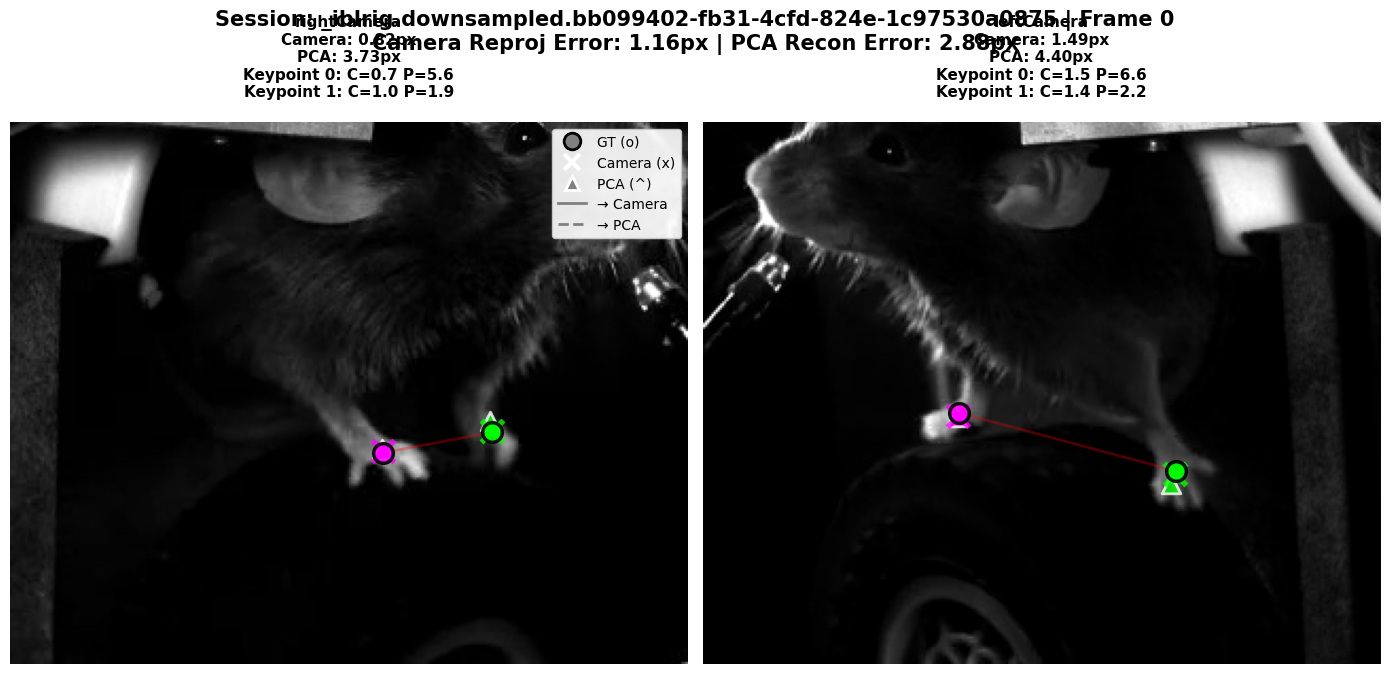


INTERPRETATION:
Camera reproj error: 1.16px
  ✅ Excellent camera calibration

PCA recon error: 2.88px
  ⚠️ PCA adds some distortion

→ PCA constraint adds more error than camera calibration (+1.73px)


In [62]:
# Cell: Visualize GT vs Camera Reprojection vs PCA Reconstruction (FIXED)
def visualize_all_three(session_name, frame_idx=0, save_path=None):
    """
    Visualize ground truth, camera reprojection, and PCA reconstruction together.
    
    - GT (circles 'o'): Original 2D labels
    - Camera Reproj (X): GT → triangulate 3D → reproject 2D (tests camera calibration)
    - PCA Recon (triangles '^'): GT → PCA reconstruction in 2D (tests PCA constraint)
    """
    
    if session_name not in session_results:
        print(f"Session '{session_name}' not found!")
        return
    
    data = session_results[session_name]
    
    # Define n_views early (FIXED)
    n_views = len(cam_names)
    
    # Get all three versions
    keypoints_2d_gt = data['keypoints_2d']  # Ground truth
    keypoints_2d_reproj = data['keypoints_2d_reproj']  # Camera reprojection
    
    # Get PCA reconstruction (need to reshape from stored format)
    if 'pca_2d_reconstructed' not in data:
        print("PCA reconstruction not found! Run PCA analysis first.")
        return
    
    pca_reconstructed = data['pca_2d_reconstructed']  # (n_frames, n_keypoints, n_views*2)
    # Reshape to (n_frames, n_views, n_keypoints, 2)
    n_frames, n_keypoints, _ = pca_reconstructed.shape
    keypoints_2d_pca = np.zeros((n_frames, n_views, n_keypoints, 2))
    for view_idx in range(n_views):
        keypoints_2d_pca[:, view_idx, :, :] = pca_reconstructed[:, :, view_idx*2:(view_idx+1)*2]
    
    image_paths = data['image_paths']
    errors_camera = data['errors']
    errors_pca = data['pca_2d_error']  # (n_frames, n_keypoints)
    
    if n_views == 2:
        rows, cols = 1, 2
    elif n_views == 6:
        rows, cols = 2, 3
    else:
        rows = int(np.ceil(np.sqrt(n_views)))
        cols = int(np.ceil(n_views / rows))
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols*7, rows*7))
    if n_views == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    # Define colors for each keypoint
    keypoint_colors = ['lime', 'magenta', 'cyan', 'yellow', 'orange', 'red', 'blue', 'green']
    keypoint_names = data_info.get('keypoint_names', [f'Keypoint {i}' for i in range(n_keypoints)])
    
    for view_idx in range(n_views):
        ax = axes[view_idx]
        
        # Load image
        img_path = image_paths[view_idx][frame_idx]
        if not Path(img_path).is_absolute():
            img_path = data_dir / img_path
        
        try:
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            if img is not None:
                ax.imshow(img, cmap='gray')
        except:
            pass
        
        # Get keypoints for this view
        kpts_gt = keypoints_2d_gt[frame_idx, view_idx]  # (n_keypoints, 2)
        kpts_camera = keypoints_2d_reproj[frame_idx, view_idx]  # (n_keypoints, 2)
        kpts_pca = keypoints_2d_pca[frame_idx, view_idx]  # (n_keypoints, 2)
        
        # Plot each keypoint with its own color
        for kp_idx in range(n_keypoints):
            color = keypoint_colors[kp_idx % len(keypoint_colors)]
            kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
            
            # 1. Ground Truth (large circle 'o')
            if not np.isnan(kpts_gt[kp_idx]).any():
                ax.scatter(kpts_gt[kp_idx, 0], kpts_gt[kp_idx, 1],
                          color=color, s=200, marker='o', edgecolors='black',
                          linewidths=2.5, label=f'{kp_name} GT', zorder=7, alpha=0.9)
            
            # 2. Camera Reprojection (X marker)
            if not np.isnan(kpts_camera[kp_idx]).any():
                ax.scatter(kpts_camera[kp_idx, 0], kpts_camera[kp_idx, 1],
                          color=color, s=250, marker='x', linewidths=4,
                          label=f'{kp_name} Camera', zorder=6, alpha=0.8)
            
            # 3. PCA Reconstruction (triangle '^')
            if not np.isnan(kpts_pca[kp_idx]).any():
                ax.scatter(kpts_pca[kp_idx, 0], kpts_pca[kp_idx, 1],
                          color=color, s=180, marker='^', edgecolors='white',
                          linewidths=2, label=f'{kp_name} PCA', zorder=5, alpha=0.8)
            
            # Draw lines from GT to both reprojections
            if not np.isnan(kpts_gt[kp_idx]).any():
                # Line to camera reprojection (solid)
                if not np.isnan(kpts_camera[kp_idx]).any():
                    ax.plot([kpts_gt[kp_idx, 0], kpts_camera[kp_idx, 0]],
                           [kpts_gt[kp_idx, 1], kpts_camera[kp_idx, 1]],
                           color=color, linewidth=2, alpha=0.4, linestyle='-', zorder=3)
                
                # Line to PCA reconstruction (dashed)
                if not np.isnan(kpts_pca[kp_idx]).any():
                    ax.plot([kpts_gt[kp_idx, 0], kpts_pca[kp_idx, 0]],
                           [kpts_gt[kp_idx, 1], kpts_pca[kp_idx, 1]],
                           color=color, linewidth=2, alpha=0.4, linestyle='--', zorder=3)
        
        # Draw skeleton on GT points (if available)
        if skeleton is not None and len(skeleton) > 0 and skeleton_colors is not None:
            valid_gt = ~np.isnan(kpts_gt).any(axis=1)
            for l, limb in enumerate(skeleton):
                if len(limb) == 2 and valid_gt[limb[0]] and valid_gt[limb[1]]:
                    ax.plot(kpts_gt[limb, 0], kpts_gt[limb, 1],
                           skeleton_colors[l], linewidth=2, alpha=0.3, zorder=2)
        
        # Calculate and display errors
        mean_camera_error = np.nanmean(errors_camera[frame_idx, view_idx, :])
        
        # For PCA error, we need to compute it per view
        pca_error_this_view = np.sqrt(np.sum((kpts_gt - kpts_pca)**2, axis=1))
        mean_pca_error = np.nanmean(pca_error_this_view)
        
        error_text = f'{cam_names[view_idx]}\n'
        error_text += f'Camera: {mean_camera_error:.2f}px\n'
        error_text += f'PCA: {mean_pca_error:.2f}px\n'
        
        # Per-keypoint errors
        for kp_idx in range(n_keypoints):
            kp_name = keypoint_names[kp_idx] if kp_idx < len(keypoint_names) else f'KP{kp_idx}'
            cam_err = errors_camera[frame_idx, view_idx, kp_idx]
            pca_err = pca_error_this_view[kp_idx]
            if not np.isnan(cam_err):
                error_text += f'{kp_name}: C={cam_err:.1f} P={pca_err:.1f}\n'
        
        ax.set_title(error_text, fontsize=11, weight='bold')
        ax.axis('off')
        
        # Legend only on first subplot
        if view_idx == 0:
            # Create custom legend
            from matplotlib.lines import Line2D
            legend_elements = [
                Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
                       markersize=12, markeredgecolor='black', markeredgewidth=2, label='GT (o)', linestyle='None'),
                Line2D([0], [0], marker='x', color='w', markerfacecolor='gray', 
                       markersize=12, markeredgewidth=3, label='Camera (x)', linestyle='None'),
                Line2D([0], [0], marker='^', color='w', markerfacecolor='gray', 
                       markersize=10, markeredgecolor='white', markeredgewidth=2, label='PCA (^)', linestyle='None'),
                Line2D([0], [0], color='gray', linewidth=2, linestyle='-', label='→ Camera'),
                Line2D([0], [0], color='gray', linewidth=2, linestyle='--', label='→ PCA'),
            ]
            ax.legend(handles=legend_elements, loc='upper right', fontsize=10, framealpha=0.9)
    
    # Hide unused subplots
    for i in range(n_views, len(axes)):
        axes[i].axis('off')
    
    overall_camera = np.nanmean(errors_camera[frame_idx])
    overall_pca = np.nanmean(errors_pca[frame_idx])
    
    title_text = f'Session: {session_name} | Frame {frame_idx}\n'
    title_text += f'Camera Reproj Error: {overall_camera:.2f}px | PCA Recon Error: {overall_pca:.2f}px'
    plt.suptitle(title_text, fontsize=15, weight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    
    plt.show()
    
    # Print interpretation
    print("\n" + "="*80)
    print("INTERPRETATION:")
    print("="*80)
    print(f"Camera reproj error: {overall_camera:.2f}px")
    if overall_camera < 2:
        print("  ✅ Excellent camera calibration")
    elif overall_camera < 5:
        print("  ⚠️ Moderate camera calibration")
    else:
        print("  ❌ Poor camera calibration")
    
    print(f"\nPCA recon error: {overall_pca:.2f}px")
    if overall_pca < 2:
        print("  ✅ PCA is a good constraint")
    elif overall_pca < 5:
        print("  ⚠️ PCA adds some distortion")
    else:
        print("  ❌ PCA is too restrictive")
    
    if overall_camera > overall_pca:
        print(f"\n→ Camera calibration is the main issue (+{overall_camera - overall_pca:.2f}px)")
    else:
        print(f"\n→ PCA constraint adds more error than camera calibration (+{overall_pca - overall_camera:.2f}px)")


# Test on a good session
good_session = [s for s, err in zip(session_names, session_means) if err < 2][0]
print(f"Visualizing GOOD session: {good_session}")
visualize_all_three(good_session, frame_idx=0)

# Test on a bad session
bad_session = [s for s, err in zip(session_names, session_means) if err > 5][0]
print(f"\n\nVisualizing BAD session: {bad_session}")
visualize_all_three(bad_session, frame_idx=0)

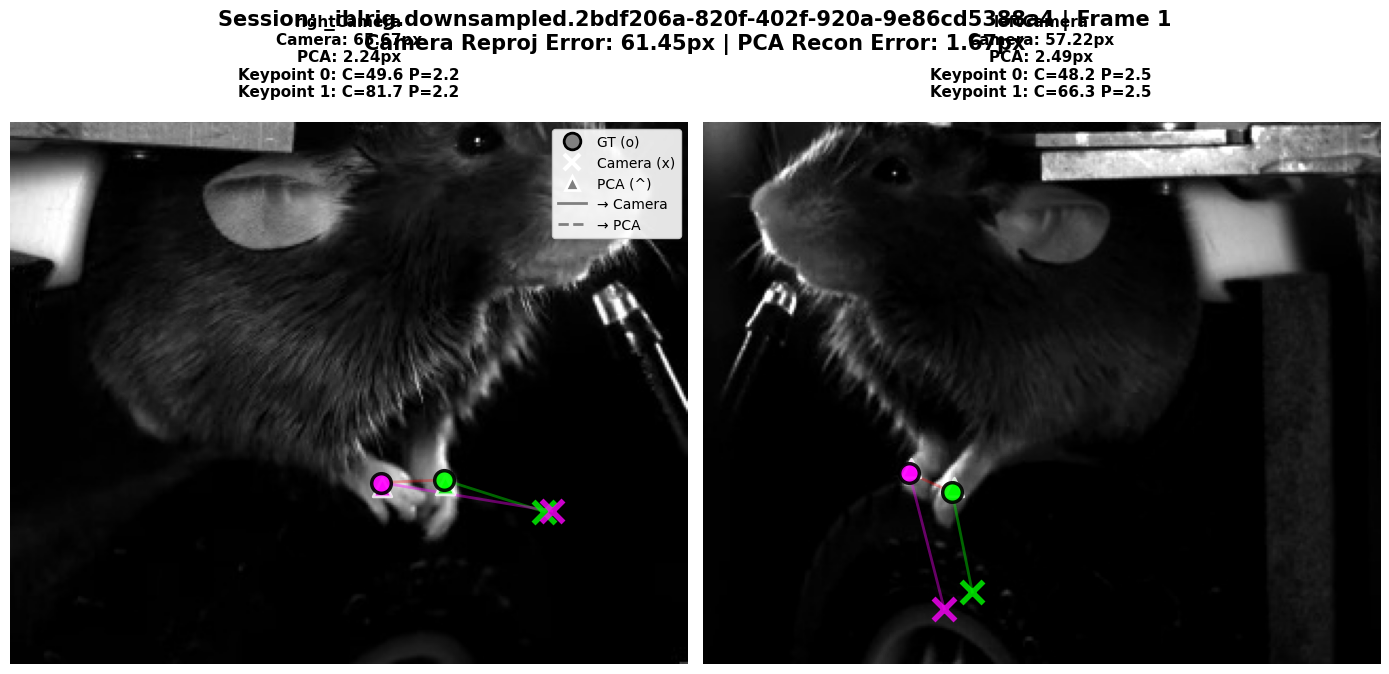


INTERPRETATION:
Camera reproj error: 61.45px
  ❌ Poor camera calibration

PCA recon error: 1.67px
  ✅ PCA is a good constraint

→ Camera calibration is the main issue (+59.77px)


In [63]:
visualize_all_three("_iblrig.downsampled.2bdf206a-820f-402f-920a-9e86cd5388a4", frame_idx =1)

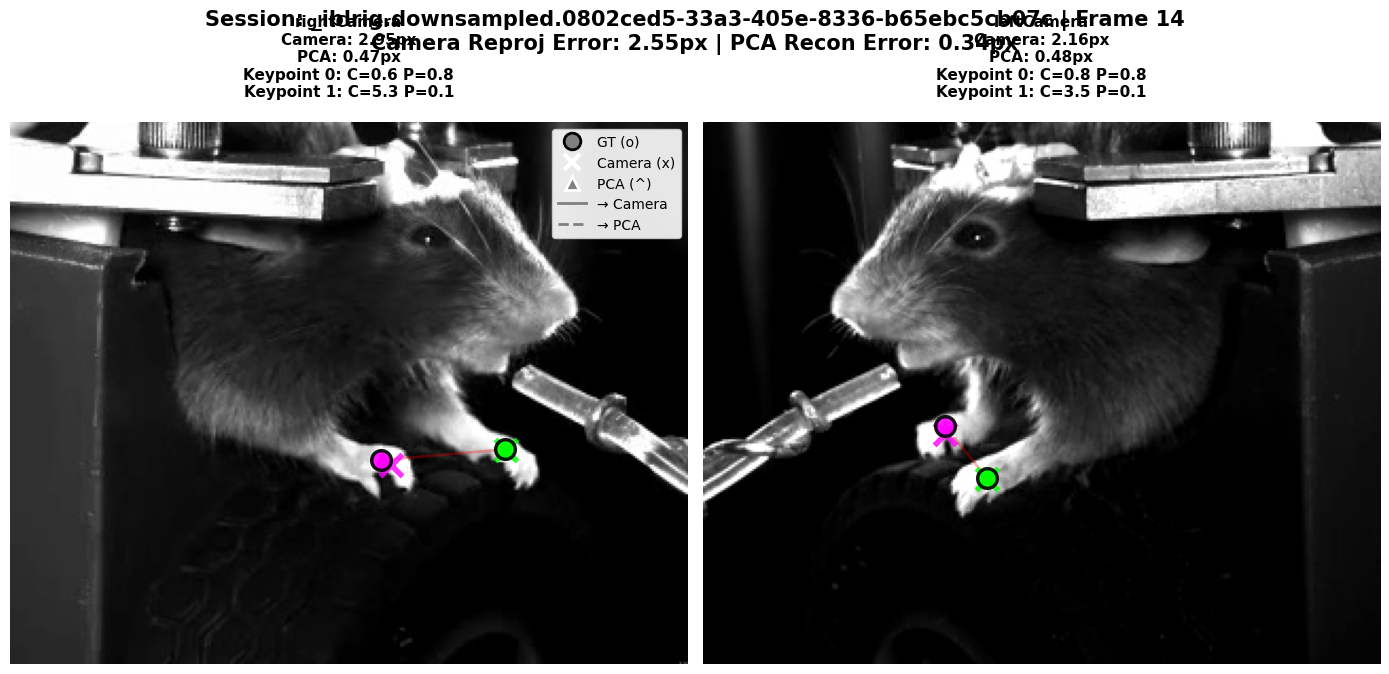


INTERPRETATION:
Camera reproj error: 2.55px
  ⚠️ Moderate camera calibration

PCA recon error: 0.34px
  ✅ PCA is a good constraint

→ Camera calibration is the main issue (+2.22px)


In [64]:
visualize_all_three("_iblrig.downsampled.0802ced5-33a3-405e-8336-b65ebc5cb07c", frame_idx =14)